# Where a coding ban takes effect in Qwen3-8B: a route-test demo

**Artifact** `art__5akZ9W9iZM4` (round 3, experiment 16) · **Model** Qwen3-8B, bf16, thinking off · **Bench** 12 frozen coding tasks (exp11)

A prompt ban such as *"Do not use a hash set of seen values for this task."* makes Qwen3-8B write a different algorithm. This
experiment asks **which internal route carries that effect**. It holds the sampling noise fixed with **common random numbers (CRN)**:
every arm of a CRN slot draws its tokens by inverse-CDF sampling from the *same* uniforms. It then **splices the KV cache** of the ban
prompt with that of a token-length-matched neutral twin, by position class. Arms differ only in the cache their generated tokens read:

| arm | cache read by the generated tokens | what it tests |
|---|---|---|
| **a** | full ban prompt | endpoint (clean) |
| **b** | neutral twin (`Do not use fire for this task. . .`) | endpoint (corrupted) |
| **c** | twin condition segment + ban task-spec and read-position states | **prompt route**: are the later prompt states sufficient? |
| **d** | ban condition segment + twin task-spec and read-position states | **direct route**: is reading the ban itself sufficient? |
| **K0** | full ban, but the condition span is invisible to every generated token | removal of the direct route |
| **V1** | twin + one-shot veto of the default's frozen distinctive n-gram | is "subtract one n-gram" the ban? |

Each program is labelled by the frozen labellers (runtime trace first, AST second, blind judge on disagreement). For a task with
default mechanism *D*, let s_X be the share of arm X's attempts labelled *D*. The route fractions are then

F_prompt = (s_b − s_c) / (s_b − s_a), F_direct = (s_b − s_d) / (s_b − s_a), I = 1 − F_prompt − F_direct, F_K0 = (s_b − s_K0) / (s_b − s_a).

**Full-run results** (13,030 CRN-coupled samples, about 1.8 GPU-hours on one L4):
- **Gate:** only 5 of 12 tasks are gated, i.e. the ban works: T03 (avoidance 0.99), T10 (1.00), T05 (0.83), T06 (0.79), T13 (0.59).
- **C2a** ("the prompt route carries ≥ 2/3 of the ban") is **DISCONFIRMED**. Pooled F_prompt = 0.611, jackknife 95% CI [0.06, 1.17];
  F_direct = 0.744, CI [0.38, 1.11]; I = −0.355; F_K0 = 0.621.
- **The mechanism is task-dependent.** T03/T10 are *redundant* (either route alone suffices). T05/T06 act through the *direct* route:
  arm d reproduces the ban, while c and K0 do not. T13 is *superadditive*: both routes are needed.
- **Prefill:** forcing the default's opening up to its first body token undoes the ban completely (P_open 0.98–1.00). A neutral
  `def` line undoes none of it. The ban takes effect at the **first content token of the body**.

**What this notebook runs** on a CPU in a few minutes. No GPU or API key is needed.
1. **S1 prompts.** Rebuilds the frozen ban/twin prompts with Qwen3-8B's tokenizer and re-runs the alignment assertions.
2. **Engine.** exp8's HF engine (KV splice, span-dropped K0, CRN inverse-CDF sampler, one-shot veto, fence stop) and the GPU
   queue's arm construction, run on a **small Qwen3 model**. It shares Qwen3-8B's tokenizer, so the frozen prompt ids are valid.
   Engine tests U1–U3 run on the same model.
3. **S9 analysis.** The original analysis code runs on `mini_demo_data.json`, a 100-slot subset of the labelled Qwen3-8B
   samples: 5 gated tasks × 5 templates × 4 CRN slots × 5 arms = 500 programs. It computes the gate, shares, route fractions
   (hierarchical bootstrap, BCa and jackknife intervals), the mixed GLM, CRN flip tables, first divergence, landing by route
   and C2c/C2b.
4. **CPU tests T3–T5.** These check the n-gram rule, the correctness of the veto redraw, and recovery of known route fractions.

**Not run here:** sampling the 13,030 programs with Qwen3-8B, and the runtime+AST+judge labelling. The labelled rows come from the run.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (the artifact pinned loguru==0.7.3)
_pip('loguru==0.7.3')

# numpy, scipy, pandas, statsmodels, matplotlib, transformers, tokenizers, huggingface_hub, torch —
# pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'statsmodels==0.14.6', 'matplotlib==3.10.0',
         'transformers==5.0.0', 'tokenizers==0.22.2', 'huggingface_hub==1.4.0')
    _pip('--extra-index-url', 'https://download.pytorch.org/whl/cpu', 'torch==2.9.0+cpu')

In [2]:
from __future__ import annotations

# ---- method.py (original import block) ----
import os
import subprocess
import sys
from pathlib import Path

from loguru import logger

# ---- src/cfg.py, src/engine.py, src/gpu.py, src/prompts_s1.py, src/forecast_s2.py, src/analysis/analysis.py,
#      tests/test_cpu.py (the modules method.py dispatches to; their code is inlined below) ----
import collections
import contextlib
import gc
import hashlib
import json
import math
import re
import time
from datetime import datetime, timezone
from typing import Any, Callable, Iterable, Iterator

import numpy as np
import torch
from scipy import stats

# ---- notebook additions (visualisation) ----
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-3/experiment-16/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

meta = data["metadata"]
EXAMPLES = data["datasets"][0]["examples"]   # the `route_arms` dataset: one example per CRN slot
DEMO_TASKS = meta["tasks"]                   # the 5 gated tasks
print(f"dataset {data['datasets'][0]['dataset']!r}: {len(EXAMPLES)} CRN slots | tasks {DEMO_TASKS} | templates "
      f"{meta['templates']} | slots k={meta['slots']} (of {meta['n_slots_full_run']}) | arms {meta['arms']}")
ex0 = EXAMPLES[0]
print("\nexample:", ex0["input"])
print(f"  output (arm a label) = {ex0['output']!r}; predict_b = {ex0['predict_b']!r}; predict_c = {ex0['predict_c']!r}; "
      f"predict_d = {ex0['predict_d']!r}; predict_K0 = {ex0['predict_K0']!r}")
print("  arm_rows (the labelled data/samples.jsonl rows of this slot):", list(ex0["arm_rows"]))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
dataset 'route_arms': 100 CRN slots | tasks ['T03', 'T06', 'T05', 'T10', 'T13'] | templates ['W1', 'W2', 'W3', 'W4', 'W5'] | slots k=[0, 1, 2, 3] (of 20) | arms ['a', 'b', 'c', 'd', 'K0']

example: task T03 | template W1 | slot k=0 | ban segment: 'Do not use a full sort for this task.' | neutral twin: 'Do not use man for this task. . .'
  output (arm a label) = 'quickselect'; predict_b = 'full_sort|pass'; predict_c = 'quickselect|pass'; predict_d = 'quickselect|pass'; predict_K0 = 'quickselect|pass'
  arm_rows (the labelled data/samples.jsonl rows of this slot): ['a', 'b', 'c', 'd', 'K0']


## Configuration

Every tunable parameter is set here, and each comment gives the original full-run value. The analysis and the CPU tests
run **at their full-run values**, which take seconds on 500 rows. Two things are reduced:
- the data: 4 of the run's 20 CRN slots per template (`N_SLOTS`);
- the engine: a small model on two CRN slots of one task. The original setting needs `ENGINE_MODEL_ID = "Qwen/Qwen3-8B"`
  on a ≥ 24 GB GPU.

The pre-registered protocol (thresholds, templates, seeds, decision rules) is **not** tunable. It stays frozen in the
`cfg` cell below, exactly as in `src/cfg.py`.

In [5]:
# ------------------------------------------------------------ S9 analysis (src/analysis/analysis.py, src/cfg.py)
N_BOOT = 10000        # hierarchical task -> template -> slot bootstrap reps for the pooled F values (original: 10000)
N_BOOT_TASK = 4000    # per-task template -> slot bootstrap reps                                   (original: 4000)
N_PERM = 100000       # permutations for the one-sided C2c Spearman test                          (original: 100000)
N_RHO_BOOT = 4000     # task-bootstrap reps for the C2c rho interval                              (original: 4000)
N_LANDING_NULL = 2000 # template -> program resampling reps of the landing null                   (original: 2000)
N_SLOTS = 4           # CRN slots per template held in mini_demo_data.json (k = 0-3)               (original: 20)
RNG_SEED = 20261020   # frozen seed of every bootstrap / permutation (src/cfg.py; not a tunable)

# ------------------------------------------------------------ CPU tests (tests/test_cpu.py)
T4_N_DRAWS = 200000   # draws in the veto-redraw chi-square test                                   (original: 200000)
T5_N_SETS = 200       # simulated datasets for the bootstrap-coverage check                        (original: 200)
T5_N_BOOT = 1000      # bootstrap reps per simulated dataset                                        (original: 1000)

# ------------------------------------------------------------ engine (src/engine.py, src/gpu.py, src/gpu_tests.py)
ENGINE_MODEL_ID = "Qwen/Qwen3-0.6B"   # shares Qwen3-8B's tokenizer, so the frozen prompt ids are valid
                                      # (original: "Qwen/Qwen3-8B" @ b968826d, bf16, one 23 GB NVIDIA L4)
ENGINE_TASKS = ["T06"]                # bench tasks sampled by the engine demo           (original: all 12 + T1/T2)
ENGINE_TEMPLATES = ["W1"]             # templates                                         (original: W1-W5)
ENGINE_SLOTS = range(1, 3)            # CRN slots k (k = 1 is the slot shown from the Qwen3-8B data below) (original: range(20))
ENGINE_ARMS = ["a", "b", "c", "d", "V1", "K0"]   # (original: also prefill, placebo, knockout-control and screen arms)
ENGINE_MAX_NEW = 128                  # max new tokens per row; a row also stops once its code fence closes (original: 1024)
ENGINE_BATCH = 5                      # rows per sampled batch, constant within a shape class (original: BRT_BATCH = 40)
ENGINE_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ENGINE_DTYPE = (torch.bfloat16 if ENGINE_DEVICE == "cuda" and torch.cuda.is_bf16_supported(including_emulation=False)
                else torch.float32)   # native bf16 GPUs (e.g. L4, A100) use bf16 as in the run; T4 and CPU use float32
print(f"engine: {ENGINE_MODEL_ID} on {ENGINE_DEVICE} ({ENGINE_DTYPE})")

engine: Qwen/Qwen3-0.6B on cpu (torch.float32)


## The pipeline behind `method.py`

`method.py` is the entry point for every stage (`uv run method.py <stage>`). It dispatches to modules in `src/`, and the
notebook inlines the code of those modules. The table maps each stage to the section that runs it here.

| `method.py` stage | module | what it does in the full run | in this notebook |
|---|---|---|---|
| `s0` | `src/s0_inputs.py` | read-only snapshot of all inputs; bench sha256 vs `commitment.json` | not run (frozen inputs ship in the data file) |
| `recheck` | `src/s0_recheck.py` | labeller re-check on references and gold sets | not run |
| `s1` | `src/prompts_s1.py` | ban / twin prompts with alignment assertions | **S1 prompts** (5 demo tasks) |
| `s2` | `src/forecast_s2.py` | frozen forecasts: distinctive n-gram rule, prefills, ASSOCIATE / PROXIMITY | n-gram rule in **CPU test T3**; frozen n-grams loaded |
| `tests` | `tests/test_cpu.py` | CPU tests T3–T5 | **CPU tests** |
| `label` | `src/labelq.py` | streaming labeller: runtime trace + AST + blind judge | not run (the rows arrive labelled) |
| `gpu` | `src/gpu.py`, `src/engine.py`, `src/gpu_tests.py` | GPU queue: every arm, U-tests, commit #2, gate, K0, prefills, screen | **Engine + U1–U3** (small model, one slot) and **gate** |
| `close1` | `src/commit.py` | append the analysis code to the hash-chained commit #1 | not run |
| `analysis` | `src/analysis/analysis.py` | S9: shares, route fractions, CRN flips, landings, C2c/C2b, prefill, screen | **sections 9.1–9.6** on the demo subset |
| `figures` / `outputs` / `audit` | `src/figures.py`, `src/outputs.py`, `audit/rederive.py` | figures, `method_out.json`, independent re-derivation | **visualisation** and the demo-vs-full-run table |

Throughout, the original code is kept as written. The changes are: inputs come from `data` instead of files under
`inputs/`, `predictions/` and `data/`; the scale parameters come from the config cell; and the GPU-only calls are
guarded so the engine also runs on a CPU. Every change is marked with a `# notebook:` comment.

The next cell holds the frozen constants and utilities of `src/cfg.py`.

In [6]:
# ---- src/cfg.py: shared constants, frozen protocol text and small utilities (paths dropped; inputs come from `data`) ----
LOG_DIR = Path("logs")  # notebook: the run's logs/ folder, next to the notebook
LOG_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------------------------------------ model
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"


def model_path() -> str:
    # notebook: the engine loads ENGINE_MODEL_ID from the config cell (was: BRT_MODEL_PATH, the HF-cache snapshot, or MODEL_ID)
    return ENGINE_MODEL_ID


def hf_kwargs() -> dict[str, str]:
    return {"revision": MODEL_REVISION} if model_path() == MODEL_ID else {}


N_LAYERS = 36
IM_END = 151645
ENDOFTEXT = 151643
MAX_NEW_TOKENS = 1024
TEMPERATURE = 1.0
DECODING = "T1.0_topp1.0_topk-off_max1024_thinkoff"
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
BATCH = 20  # constant batch shape for every sampled batch (two CRN blocks of 10); see deviations

# ------------------------------------------------------------------------------------------------ bench
STAGE_A = ["T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11"]
TASK_DIR = {"T03": "T03_kth_smallest", "T04": "T04_substring_search", "T06": "T06_find_duplicate",
            "T05": "T05_two_sum", "T10": "T10_connected_components", "R1": "R1_non_overlapping_intervals",
            "T08": "T08_fibonacci", "R3": "R3_topological_order", "T13": "T13_merge_intervals",
            "R6": "R6_first_last_position", "T14": "T14_top_k_frequent", "T11": "T11_longest_increasing_subsequence"}
DEFAULT = {"T03": "full_sort", "T04": "naive", "T06": "hash_set", "T05": "hash_map", "T10": "union_find",
           "R1": "greedy_end", "T08": "iteration", "R3": "kahn", "T13": "sort_sweep", "R6": "binary_search",
           "T14": "sort_by_count", "T11": "quadratic_dp"}
PATH_TASKS = ("t1", "t2")
PATH_DEFAULT = {"t1": "bfs", "t2": "dijkstra"}
PATH_SUB = {"t1": "dfs", "t2": "bf_spfa"}
ALL_TASKS = STAGE_A + list(PATH_TASKS)

# W1-W5 (ban, mention, neutral) verbatim from the shared protocol v2 (exp8 cfg.TEMPLATES).
TEMPLATES: dict[str, tuple[str, str, str]] = {
    "W1": ("Do not use {X} for this task.", "You could use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution may rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Consider {X} first.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{X} is allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that may use {X}.",
           "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES.keys())
FILLER = " ."  # exp7 frozen neutral-twin padding filler
N_PER_TEMPLATE = 20
BLOCK = 10

THRESHOLDS = {
    "F_confirm": 2.0 / 3.0, "F_ci_lower": 0.5, "F_direct_disconfirm": 1.0 / 3.0,
    "gate_avoidance": 0.5, "gate_min_nondefault": 20,
    "veto_low_direct": 0.8, "veto_high_direct": 0.5, "pred_low_direct_F": 0.15, "pred_high_direct_F": 0.25,
    "veto_min_fire_rate": 0.5, "c2c_hit_fraction": 2.0 / 3.0, "c2c_disconfirm_hit": 0.5, "c2c_alpha": 0.05,
    "ngram_presence": 0.8, "coveto": 0.5, "reemerge": 0.2, "screen_min_nond": 20, "placebo_tol": 0.1,
    "c2b_eligible_V": 0.5, "c2b_task_share": 2.0 / 3.0,
}
# N_BOOT, N_PERM and RNG_SEED: see the config cell


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def stable_seed(*parts: Any) -> int:
    """exp8: deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr)."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def chat_ids(tok: Any, user_text: str) -> list[int]:
    s = chat_text(tok, user_text)
    return list(tok(s, add_special_tokens=False).input_ids)


def chat_text(tok: Any, user_text: str) -> str:
    s = tok.apply_chat_template([{"role": "user", "content": user_text}], tokenize=False,
                                add_generation_prompt=True, enable_thinking=False)
    assert s.endswith(TEMPLATE_TAIL), repr(s[-80:])
    return s


def resp_ids(tok: Any, code: str) -> list[int]:
    """Frozen protocol: resp(code) = tokens of '```python\\n' + code.rstrip('\\n') + '\\n```'."""
    return list(tok("```python\n" + code.rstrip("\n") + "\n```", add_special_tokens=False).input_ids)


def default_of(task: str) -> str:
    return PATH_DEFAULT[task] if task in PATH_TASKS else DEFAULT[task]


setup_logging("method_demo")  # method.py: setup_logging(f"method_{stage}")
logger.info(f"frozen protocol: {len(STAGE_A)} bench tasks, templates {TEMPLATE_IDS}, seed {RNG_SEED}")

07:28:14|INFO   |frozen protocol: 12 bench tasks, templates ['W1', 'W2', 'W3', 'W4', 'W5'], seed 20261020


## S1 — ban and neutral-twin prompts (`method.py s1` → `src/prompts_s1.py`)

A bench prompt is the Qwen3 chat template (thinking off) around `cap_first(cond) + "\n\n" + spec_text`.

- **Ban:** `cond` is template W_w's ban sentence, with X set to the display name of the task's default mechanism, e.g. *"a hash set of seen values"*.
- **Twins:** twin_A and twin_B use the same template's neutral sentence with a neutral concrete noun A or B. Each twin is padded
  with `" ."` until it has exactly as many tokens as the ban (exp7's frozen rule).

The asserts guarantee that ban and twin are **identical everywhere except the condition segment [p0, p1)**. They have the same
length, the same ids before p0 = 3, and the same ids from p1 (the first token of `Task:`) onward. Position classes are therefore
well defined for splicing: [0, p1) is the condition part and [p1, P) the task-spec and read part.

The cell below rebuilds the 75 prompts of the 5 demo tasks with Qwen3-8B's own tokenizer (pinned revision, tokenizer files only,
about 11 MB). It re-runs every assertion and checks that the ids are identical to the frozen `prompts/prompts.jsonl` the run
sampled from.

In [7]:
# ---- method.py: _tok() (the tokenizer handed to the s1 / s2 stages) ----
def _tok():
    from transformers import AutoTokenizer

    # notebook: Qwen3-8B's tokenizer at the pinned revision, tokenizer files only (was: from_pretrained(model_path()))
    return AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)


# ---- src/prompts_s1.py (bench prompts) ----
def spec(task: str) -> dict[str, Any]:
    return meta["tasks_spec"][task]  # notebook: was read_json(BENCH / TASK_DIR[task] / "spec.json")


def display_name(task: str, mode: str) -> str:
    for c in spec(task)["catalogue"]:
        if c["mode"] == mode:
            return c["display_name"]
    raise KeyError((task, mode))


def nouns(task: str) -> list[str]:
    nn = {default_of(task): spec(task)["neutral_nouns"]}  # notebook: was read_json(BENCH / TASK_DIR[task] / "neutral_nouns.json")
    return [n["word"] for n in nn[default_of(task)]["nouns"]]


def user_text(task: str, cond: str) -> str:
    return cap_first(cond) + "\n\n" + spec(task)["spec_text"]


def find_p1(tok: Any, chat: str, ids: list[int]) -> int:
    """Index of the first token of 'Task:' (the spec), asserting a clean token boundary there."""
    pos = chat.index("\n\nTask:") + 2
    enc = tok(chat, add_special_tokens=False, return_offsets_mapping=True)
    assert list(enc.input_ids) == ids
    for i, (s, _e) in enumerate(enc.offset_mapping):
        if s >= pos:
            assert s == pos, f"'Task:' does not start a token (token {i} starts at {s}, want {pos})"
            return i
    raise AssertionError("no token at 'Task:'")


def build_bench(tok: Any, tasks: list[str] = STAGE_A) -> list[dict[str, Any]]:  # notebook: `tasks` (was: every STAGE_A task)
    rows = []
    for t in tasks:
        D = default_of(t)
        X = display_name(t, D)
        nA, nB = nouns(t)
        for w in TEMPLATE_IDS:
            ban_cond = TEMPLATES[w][0].replace("{X}", X)
            ban_chat = chat_text(tok, user_text(t, ban_cond))
            ban_ids = chat_ids(tok, user_text(t, ban_cond))
            p1 = find_p1(tok, ban_chat, ban_ids)
            out = {"ban": {"cond": ban_cond, "ids": ban_ids, "noun": None, "pad": 0}}
            for lab, noun in (("twin_A", nA), ("twin_B", nB)):
                base = TEMPLATES[w][2].replace("{N}", noun)
                d = len(ban_ids) - len(chat_ids(tok, user_text(t, base)))
                cond = base + FILLER * max(0, d)
                ids = chat_ids(tok, user_text(t, cond))
                out[lab] = {"cond": cond, "ids": ids, "noun": noun, "pad": max(0, d)}
            P = len(ban_ids)
            p0 = 3
            for lab in ("twin_A", "twin_B"):
                ids = out[lab]["ids"]
                assert len(ids) == P, (t, w, lab, len(ids), P)
                assert ids[p1:] == ban_ids[p1:], (t, w, lab)
                assert ids[:p0] == ban_ids[:p0], (t, w, lab)
                diff = [i for i in range(P) if ids[i] != ban_ids[i]]
                assert diff and min(diff) >= p0 and max(diff) < p1, (t, w, lab, diff, p0, p1)
                assert find_p1(tok, chat_text(tok, user_text(t, out[lab]["cond"])), ids) == p1
            for kind, v in out.items():
                rows.append({"task": t, "w": w, "kind": kind, "noun": v["noun"], "cond": v["cond"], "pad": v["pad"],
                             "ids": v["ids"], "p0": p0, "p1": p1, "P": P,
                             "prompt_sha256": sha256_text(",".join(map(str, v["ids"])))})
    return rows


def load_prompts() -> dict[tuple[str, str, str], dict[str, Any]]:
    return {(r["task"], r["w"], r["kind"]): r for r in PROMPT_ROWS}  # notebook: was read_jsonl(PROMPTS_FILE)


t0 = time.time()
tok = _tok()
PROMPT_ROWS = build_bench(tok, DEMO_TASKS)
logger.info(f"S1: {len(PROMPT_ROWS)} prompt rows; all alignment assertions passed ({time.time() - t0:.1f}s)")

# notebook check: the rebuilt prompts are identical to the frozen prompts/prompts.jsonl rows the run sampled from
frozen = meta["prompts"]
same = [r["prompt_sha256"] == frozen[f"{r['task']}|{r['w']}|{r['kind']}"]["prompt_sha256"] for r in PROMPT_ROWS]
print(f"rebuilt prompt ids identical to the frozen ones: {sum(same)}/{len(same)}\n")
pr = load_prompts()
for t in DEMO_TASKS:
    b = pr[(t, "W1", "ban")]
    print(f"{t} W1  P={b['P']}  [p0, p1)=[{b['p0']}, {b['p1']})  ban: {b['cond']!r}  |  twin_A: {pr[(t, 'W1', 'twin_A')]['cond']!r}")
print("\nT06 / W1 ban prompt exactly as the model reads it:\n" + tok.decode(pr[("T06", "W1", "ban")]["ids"]))

07:28:16|INFO   |S1: 75 prompt rows; all alignment assertions passed (2.7s)


rebuilt prompt ids identical to the frozen ones: 75/75

T03 W1  P=188  [p0, p1)=[3, 13)  ban: 'Do not use a full sort for this task.'  |  twin_A: 'Do not use man for this task. . .'
T06 W1  P=142  [p0, p1)=[3, 16)  ban: 'Do not use a hash set of seen values for this task.'  |  twin_A: 'Do not use fire for this task. . . . . .'
T05 W1  P=175  [p0, p1)=[3, 16)  ban: 'Do not use a hash map of seen values for this task.'  |  twin_A: 'Do not use face for this task. . . . . .'
T10 W1  P=172  [p0, p1)=[3, 18)  ban: 'Do not use union-find (disjoint set union) for this task.'  |  twin_A: 'Do not use ship for this task. . . . . . . .'
T13 W1  P=183  [p0, p1)=[3, 15)  ban: 'Do not use sorting and a single sweep for this task.'  |  twin_A: 'Do not use tape for this task. . . . .'

T06 / W1 ban prompt exactly as the model reads it:
<|im_start|>user
Do not use a hash set of seen values for this task.

Task: write a Python function solve(nums) that returns the repeated value in nums. The argument num

## The engine: KV splicing, knockout and CRN sampling (`src/engine.py`)

This is exp8's HF engine, ported and extended for this experiment. The cell is the module verbatim, except that
`load_model` also runs on a CPU. Its building blocks:

- **`prefill(model, ids)`** runs the prompt once and keeps every layer's K/V cache, plus the logits at the read position (R).
- **`splice(kv_a, kv_b, cut)`** takes positions [0, cut) from A and [cut, P) from B in every layer.
  - Arm **c** = `splice(twin, ban, p1)` with the ban's R logits. Generated tokens see the twin's condition segment but the ban's task-spec states, which were computed *after* reading the ban.
  - Arm **d** = `splice(ban, twin, p1)` with the twin's R logits. Generated tokens can read the ban sentence directly, but the later prompt states are the twin's.
- **`drop_span(kv, p0, p1)`** (arm **K0**) removes the condition span from the cache. Keys keep their RoPE rotation and generated
  queries keep positions P + step, so this equals exp8's masked knockout; test U3 below checks that.
- **`sample(...)`** does CRN sampling. Each row has its own uniform stream `u_stream('beh', task, template, k)`, and the token
  at step *t* is the first vocabulary index whose float64 CDF reaches u_t.
  - Every arm of a slot uses the same uniforms, so two arms emit identical tokens until their next-token distributions differ enough to cross a CDF boundary.
  - A **one-shot veto** (arm V1) masks the default's frozen n-gram the first time it would complete. It redraws from the renormalised distribution with a *fresh* uniform from a separate stream.
  - A row stops once its first fenced code block closes (**fence stop**).

In [8]:
# ---- src/engine.py: HF engine for Qwen3-8B bf16, ported from exp8's engine.py (art_8_ULPE8jJQc_) and extended ----
KO: dict[str, Any] = {"active": False, "p0": 0, "p1": 0, "P": 0, "g_lo": 0, "g_hi": 10 ** 9, "layers": None,
                      "rowmask": None}
RECORD: dict[str, Any] = {"on": False, "weights": {}}
_REGISTERED = False

# bench extractor (exp11 harness.FENCE_RE) and exp8 suite extractor (closed python block)
BENCH_FENCE = re.compile(r"```[ \t]*(?:python3?|py|Python)?[ \t]*\n(.*?)```", re.S)
PATH_FENCE = re.compile(r"```(?:python|py|Python|python3)[ \t]*\n(.*?)```", re.S)


def fence_closed_bench(text: str) -> bool:
    return BENCH_FENCE.search(text) is not None


def fence_closed_path(text: str) -> bool:
    m = PATH_FENCE.search(text)
    return bool(m and m.group(1).strip())


# ------------------------------------------------------------------------------------------------ attention
def _ko_on(module: Any) -> bool:
    return bool(KO["active"]) and (KO["layers"] is None or module.layer_idx in KO["layers"])


def _ko_allowed(q_len: int, k_len: int, device: torch.device) -> torch.Tensor:
    offset = k_len - q_len
    qpos = torch.arange(offset, k_len, device=device)
    kpos = torch.arange(k_len, device=device)
    allowed = kpos[None, :] <= qpos[:, None]
    g = qpos - int(KO["P"])
    qblock = (g >= int(KO["g_lo"])) & (g < int(KO["g_hi"]))
    kblock = (kpos >= int(KO["p0"])) & (kpos < int(KO["p1"]))
    return allowed & ~(qblock[:, None] & kblock[None, :])


def _combine(allowed: torch.Tensor, attention_mask: torch.Tensor | None, k_len: int) -> torch.Tensor:
    allowed = allowed[None, None]
    if attention_mask is not None:
        am = attention_mask[:, :, :, :k_len]
        if am.dtype == torch.bool:
            allowed = allowed & am
        else:
            allowed = allowed & (am == 0)
    return allowed


def ko_sdpa(module, query, key, value, attention_mask, **kwargs):
    from transformers.integrations.sdpa_attention import sdpa_attention_forward

    rm = KO.get("rowmask")
    if rm is not None:  # sampling: one explicit [B,1,q,k] boolean mask for every layer (q = 1 at decode)
        kwargs.pop("is_causal", None)
        return sdpa_attention_forward(module, query, key, value, rm[:, :, :, :key.shape[2]], is_causal=False, **kwargs)
    if _ko_on(module):
        q_len, k_len = query.shape[2], key.shape[2]
        allowed = _combine(_ko_allowed(q_len, k_len, query.device), attention_mask, k_len)
        kwargs.pop("is_causal", None)
        return sdpa_attention_forward(module, query, key, value, allowed, is_causal=False, **kwargs)
    return sdpa_attention_forward(module, query, key, value, attention_mask, **kwargs)


def ko_eager(module, query, key, value, attention_mask, **kwargs):
    """Eager twin used only by the knockout-correctness test (U3); records attention probabilities."""
    from transformers.models.qwen3.modeling_qwen3 import eager_attention_forward

    q_len, k_len = query.shape[2], key.shape[2]
    if _ko_on(module):
        allowed = _combine(_ko_allowed(q_len, k_len, query.device), attention_mask, k_len)
    else:
        base = torch.ones(q_len, k_len, dtype=torch.bool, device=query.device).tril(k_len - q_len)
        allowed = _combine(base, attention_mask, k_len)
    fmask = torch.zeros(allowed.shape, dtype=query.dtype, device=query.device)
    fmask = fmask.masked_fill(~allowed, torch.finfo(query.dtype).min)
    out, w = eager_attention_forward(module, query, key, value, fmask, **kwargs)
    if RECORD["on"]:
        RECORD["weights"][module.layer_idx] = w.detach().float().cpu()
    return out, w


def register() -> None:
    global _REGISTERED
    if _REGISTERED:
        return
    from transformers import AttentionInterface
    from transformers.masking_utils import AttentionMaskInterface, eager_mask, sdpa_mask

    AttentionInterface.register("ko_sdpa", ko_sdpa)
    AttentionInterface.register("ko_eager", ko_eager)
    AttentionMaskInterface.register("ko_sdpa", sdpa_mask)
    AttentionMaskInterface.register("ko_eager", eager_mask)
    _REGISTERED = True


@contextlib.contextmanager
def knockout(cfg: dict[str, Any] | None) -> Iterator[None]:
    """cfg: {'p0','p1','P','g_lo','g_hi','layers'} or None (no knockout). Used by score() and prefill-time tests."""
    old = dict(KO)
    try:
        if cfg is not None:
            KO.update({"active": True, "g_lo": 0, "g_hi": 10 ** 9, "layers": None})
            KO.update(cfg)
        else:
            KO["active"] = False
        yield
    finally:
        KO.clear()
        KO.update(old)


def set_attn(model: Any, name: str) -> None:
    model.config._attn_implementation = name
    for m in model.modules():
        if hasattr(m, "config") and m.config is not model.config and hasattr(m.config, "_attn_implementation"):
            m.config._attn_implementation = name


def load_model(vram_fraction: float = 0.95):
    from transformers import AutoModelForCausalLM, AutoTokenizer
    from transformers.utils import logging as hf_logging

    hf_logging.disable_progress_bar()  # notebook: keeps the weight-loading bar out of the saved cell output
    hf_logging.set_verbosity_error()   # notebook: and the small model's harmless tied-weights notice
    register()
    t0 = time.time()
    tok = AutoTokenizer.from_pretrained(model_path(), **hf_kwargs())
    # notebook: ENGINE_DTYPE on ENGINE_DEVICE (CUDA bf16 when available, else CPU float32);
    # the run loaded dtype=torch.bfloat16 with device_map={"": 0}
    model = AutoModelForCausalLM.from_pretrained(model_path(), dtype=ENGINE_DTYPE, attn_implementation="ko_sdpa",
                                                 **hf_kwargs()).to(ENGINE_DEVICE)
    model.eval()
    if ENGINE_DEVICE == "cuda":  # notebook: the VRAM cap and report need a GPU
        torch.cuda.set_per_process_memory_fraction(vram_fraction, 0)
        free, total = torch.cuda.mem_get_info(0)
        logger.info(f"free VRAM {free / 1e9:.1f}/{total / 1e9:.1f} GB")
    logger.info(f"HF model loaded in {time.time() - t0:.0f}s; attn={model.config._attn_implementation}; "
                f"{model_path()} on {ENGINE_DEVICE}")
    return tok, model


# ------------------------------------------------------------------------------------------------ caches
def _kv_list(cache: Any) -> list[tuple[torch.Tensor, torch.Tensor]]:
    if hasattr(cache, "layers"):
        return [(L.keys, L.values) for L in cache.layers]
    return list(zip(cache.key_cache, cache.value_cache))


def build_cache(kv: list[tuple[torch.Tensor, torch.Tensor]], batch: int = 1):
    from transformers.cache_utils import DynamicCache

    cache = DynamicCache()
    for l, (K, V) in enumerate(kv):
        if K.shape[0] != batch:
            K = K.expand(batch, -1, -1, -1)
            V = V.expand(batch, -1, -1, -1)
        cache.update(K.contiguous(), V.contiguous(), l)
    return cache


@torch.no_grad()
def prefill(model: Any, ids: list[int]) -> dict[str, Any]:
    """Returns {'kv': per-layer (K, V) [1, 8, P, 128] on GPU, 'r_logits': float32 [V], 'P'}."""
    from transformers.cache_utils import DynamicCache

    inp = torch.tensor([ids], device=model.device)
    cache = DynamicCache()
    out = model.model(input_ids=inp, past_key_values=cache, use_cache=True)
    r_logits = model.lm_head(out.last_hidden_state[:, -1]).float()[0]
    kv = [(K.clone(), V.clone()) for K, V in _kv_list(cache)]
    del cache, out
    return {"kv": kv, "r_logits": r_logits, "P": len(ids)}


def splice(kv_a: list, kv_b: list, cut: int) -> list:
    """Positions [0, cut) from A and [cut, P) from B, every layer."""
    return [(torch.cat([Ka[:, :, :cut], Kb[:, :, cut:]], dim=2), torch.cat([Va[:, :, :cut], Vb[:, :, cut:]], dim=2))
            for (Ka, Va), (Kb, Vb) in zip(kv_a, kv_b)]


def drop_span(kv: list, p0: int, p1: int) -> list:
    """K0 without a mask: remove the condition span [p0, p1) from every layer's cache. Keys carry their RoPE rotation
    from prefill and generated queries keep position ids P + step, so attention of every generated query over the
    remaining keys equals exp8's masked knockout (softmax renormalises over the unmasked keys) -- see test U3."""
    return [(torch.cat([K[:, :, :p0], K[:, :, p1:]], dim=2), torch.cat([V[:, :, :p0], V[:, :, p1:]], dim=2))
            for K, V in kv]


def replace_positions(kv_base: list, kv_src: list, positions: list[int]) -> list:
    out = []
    idx = torch.tensor(positions, device=kv_base[0][0].device)
    for (Kb, Vb), (Ks, Vs) in zip(kv_base, kv_src):
        K, V = Kb.clone(), Vb.clone()
        K[:, :, idx] = Ks[:, :, idx]
        V[:, :, idx] = Vs[:, :, idx]
        out.append((K, V))
    return out


# ------------------------------------------------------------------------------------------------ scoring
@torch.no_grad()
def _token_logprobs(model: Any, h: torch.Tensor, tgt: torch.Tensor, chunk: int = 256) -> torch.Tensor:
    out = []
    for i in range(0, h.shape[0], chunk):
        logits = model.lm_head(h[i:i + chunk]).float()
        out.append(torch.log_softmax(logits, dim=-1).gather(-1, tgt[i:i + chunk, None])[:, 0])
    return torch.cat(out) if out else torch.zeros(0, device=h.device)


@torch.no_grad()
def score(model: Any, arm: dict[str, Any], seqs: list[list[int]], ko: dict[str, Any] | None = None) -> list[np.ndarray]:
    """exp8: teacher-forced per-token log-probs of each sequence placed after the arm's prompt cache, batch 1.
    Token 0 is scored with the arm's R logits; token t >= 1 with the hidden state at position P + t - 1."""
    kv, r_logits = arm["kv"], arm["r_logits"]
    P = kv[0][0].shape[2]
    r_lp = torch.log_softmax(r_logits.float(), dim=-1)
    res = []
    for s in seqs:
        T = len(s)
        inp = torch.tensor([s], device=model.device)
        cache = build_cache(kv, 1)
        pos = torch.arange(P, P + T, device=model.device)[None]
        kcfg = None if ko is None else {**ko, "P": P}
        with knockout(kcfg):
            h = model.model(input_ids=inp, past_key_values=cache, position_ids=pos, use_cache=True).last_hidden_state
        lp = _token_logprobs(model, h[0, :T - 1], inp[0, 1:T])
        first = r_lp[s[0]].reshape(1)
        res.append(torch.cat([first, lp]).float().cpu().numpy())
        del cache, h, inp
    return res


# ------------------------------------------------------------------------------------------------ sampling
def u_stream(*key: Any, n: int = MAX_NEW_TOKENS) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


def _inverse_cdf(probs: torch.Tensor, u: torch.Tensor) -> torch.Tensor:
    cdf = probs.cumsum(dim=-1)
    cdf = cdf / cdf[:, -1:]
    tok = torch.searchsorted(cdf, u[:, None].to(cdf.dtype)).squeeze(-1)
    return tok.clamp_(max=probs.shape[-1] - 1)


def _completing_ids(gen: list[int], ngrams: list[list[int]]) -> set[int]:
    """Ids that would complete any n-gram given the row's generated tail."""
    out = set()
    for g in ngrams:
        n = len(g)
        if n == 1 or (len(gen) >= n - 1 and gen[len(gen) - (n - 1):] == g[:-1]):
            out.add(int(g[-1]))
    return out


@torch.no_grad()
def sample(model: Any, rows: list[dict[str, Any]], max_new: int = MAX_NEW_TOKENS, temperature: float = 1.0,
           tick_ids: set[int] | None = None, decode: Callable[[list[int]], str] | None = None,
           prune_after: int | None = None) -> list[dict[str, Any]]:
    """rows: [{'kv': per-layer (K,V) [1,8,P,128], 'r_logits': [V], 'u': np.ndarray[max_new],
               optional 'u2': np.ndarray (veto redraw stream), 'veto': {'mode': 'oneshot'|'persistent',
               'ngrams': [[ids]]}, 'ko': (p0, p1) or None, 'stop': 'bench'|'path'|None, 'prefix_text': str}]
    All rows share P. One uniform per (row, step); token = first index whose CDF >= u. Finished rows stay in the batch
    (fed <|im_end|>) so the shape is constant; prune_after (memory guard) drops finished rows after that step."""
    B = len(rows)
    P = rows[0]["kv"][0][0].shape[2]          # cache length (shorter than the prompt for span-dropped K0 rows)
    pos0 = int(rows[0].get("pos0", P))        # position id of the first generated token (= prompt length)
    assert all(r["kv"][0][0].shape[2] == P and int(r.get("pos0", P)) == pos0 for r in rows)
    dev = model.device
    kv = [(torch.cat([r["kv"][l][0] for r in rows], 0), torch.cat([r["kv"][l][1] for r in rows], 0))
          for l in range(len(rows[0]["kv"]))]
    cache = build_cache(kv, B)
    del kv
    # explicit per-row mask only in batches that hold knockout rows (an explicit mask disables SDPA's native GQA
    # path, so knockout batches run a different kernel -- K0 is CRN-coupled to the other arms only approximately,
    # exactly as in exp8); every other batch runs stock SDPA with no mask
    rowmask = None
    if any(r.get("ko") for r in rows):
        rowmask = torch.ones((B, 1, 1, P + max_new + 1), dtype=torch.bool, device=dev)
        for i, r in enumerate(rows):
            if r.get("ko"):
                p0, p1 = r["ko"]
                rowmask[i, :, :, p0:p1] = False
    U = torch.tensor(np.stack([r["u"][:max_new] for r in rows]), dtype=torch.float64, device=dev)
    logits = torch.stack([r["r_logits"] for r in rows]).double()
    alive = list(range(B))
    toks: list[list[int]] = [[] for _ in range(B)]
    lps: list[list[float]] = [[] for _ in range(B)]
    finish = ["length"] * B
    done: set[int] = set()
    veto = [r.get("veto") for r in rows]
    fired = [False] * B
    fire_step: list[int | None] = [None] * B
    n_redraw = [0] * B
    redraw_steps: list[list[int]] = [[] for _ in range(B)]
    n_compl = [0] * B
    pruned_at = None
    step = 0
    while True:
        probs = torch.softmax(logits / temperature, dim=-1)
        nxt_t = _inverse_cdf(probs, U[alive, step])
        nxt = nxt_t.tolist()
        # vetoes (rare events; handled per row on the CPU side)
        for j, r in enumerate(alive):
            v = veto[r]
            if v is None or r in done:
                continue
            comp = _completing_ids(toks[r], v["ngrams"])
            if not comp or nxt[j] not in comp:
                continue
            n_compl[r] += 1
            if v["mode"] == "oneshot":
                if fired[r]:
                    continue
                mask_ids = {nxt[j]}
            else:
                mask_ids = comp
            p = probs[j].clone()
            p[list(mask_ids)] = 0.0
            if float(p.sum()) <= 0:
                continue
            u2 = float(rows[r]["u2"][n_redraw[r]])
            nxt[j] = int(_inverse_cdf((p / p.sum())[None], torch.tensor([u2], dtype=torch.float64, device=dev))[0])
            n_redraw[r] += 1
            redraw_steps[r].append(step)
            if not fired[r]:
                fired[r] = True
                fire_step[r] = step
        nxt_dev = torch.tensor(nxt, device=dev)
        plp = torch.log(probs.gather(-1, nxt_dev[:, None])[:, 0]).tolist()
        keep = []
        for j, (r, t) in enumerate(zip(alive, nxt)):
            if r in done:
                continue
            toks[r].append(int(t))
            lps[r].append(float(plp[j]))
            if t in (IM_END, ENDOFTEXT):
                finish[r] = "stop"
                done.add(r)
                continue
            st = rows[r].get("stop")
            if st and tick_ids is not None and decode is not None and int(t) in tick_ids:
                text = rows[r].get("prefix_text", "") + decode(toks[r])
                if (fence_closed_bench(text) if st == "bench" else fence_closed_path(text)):
                    finish[r] = "fence"
                    done.add(r)
                    continue
            if len(toks[r]) < max_new:
                keep.append(j)
            else:
                done.add(r)
        if not keep:
            break
        if prune_after is not None and step >= prune_after and len(keep) < len(alive):
            idx = torch.tensor(keep, device=dev)
            if hasattr(cache, "batch_select_indices"):
                cache.batch_select_indices(idx)
            else:
                kvn = [(K[idx], V[idx]) for K, V in _kv_list(cache)]
                cache = build_cache(kvn, len(keep))
            if rowmask is not None:
                rowmask = rowmask[idx]
            alive = [alive[j] for j in keep]
            nxt = [nxt[j] for j in keep]
            if pruned_at is None:
                pruned_at = step
        else:
            nxt = [IM_END if r in done else t for r, t in zip(alive, nxt)]
        inp = torch.tensor(nxt, device=dev)[:, None]
        pos = torch.full((len(alive), 1), pos0 + step, device=dev, dtype=torch.long)
        KO["rowmask"] = rowmask
        try:
            h = model.model(input_ids=inp, past_key_values=cache, position_ids=pos, use_cache=True).last_hidden_state
        finally:
            KO["rowmask"] = None
        logits = model.lm_head(h[:, -1]).double()
        step += 1
    del cache
    return [{"token_ids": toks[r], "finish_reason": finish[r], "n_tokens": len(toks[r]),
             "logprob_sum": float(np.sum(lps[r])), "veto_fired": fired[r], "fire_step": fire_step[r],
             "n_redraws": n_redraw[r], "redraw_steps": redraw_steps[r], "n_completions_drawn": n_compl[r],
             "pruned_at": pruned_at, "steps": step} for r in range(B)]


def free(*objs: Any) -> None:
    for o in objs:
        del o
    gc.collect()
    torch.cuda.empty_cache()


def logmeanexp(x: np.ndarray) -> float:
    x = np.asarray(x, dtype=np.float64)
    m = np.max(x)
    return float(m + math.log(np.mean(np.exp(x - m))))


# notebook: the CRN key of a slot reproduces the seed recorded on every Qwen3-8B row of that slot
print("stable_seed('beh', 'T06', 'W1', 1) =", stable_seed("beh", "T06", "W1", 1), "| first uniforms:",
      np.round(u_stream("beh", "T06", "W1", 1, n=5), 4))

stable_seed('beh', 'T06', 'W1', 1) = 6666425756183774977 | first uniforms: [0.3488 0.4312 0.597  0.2492 0.992 ]


### The GPU queue's arm construction and batch runner (`method.py gpu` → `src/gpu.py`)

`Worker.arm_state` builds the cache each arm reads; the arm table at the top lists what goes into each. `run_rows` groups
rows into **shape classes** of equal cache length and first position, and pads every batch to a constant `B` with discarded
duplicates. CRN partners therefore always meet identical kernels; U1/U2 = 1.00 in the run. K0 rows have a shorter cache
(the span is dropped), so they form their own class.

Below is the original class with these notebook changes: prompts come from the S1 cell, frozen n-grams from `data`,
generated rows are kept in memory (`ENGINE_ROWS`) instead of being appended to `data/samples_raw.jsonl`, and `max_new` comes
from the config cell.

In [9]:
# ---- src/gpu.py: arm construction and the shape-class batch runner of the GPU queue ----
TIMING: dict[str, Any] = {"batches": [], "stages": {}, "decisions": []}
ATTEMPT_EXCLUDE = ("invalid", "no_code", "disputed")
ENGINE_ROWS: list[dict[str, Any]] = []  # notebook: generated rows stay in memory (was: appended to data/samples_raw.jsonl)


def u_key(task: str, w: str, k: int) -> tuple:
    return ("beh", task, w, k)  # exp8's behaviour key: the T1/T2 screen and U9 reuse exp8's uniforms exactly


class Worker:
    def __init__(self, B: int, deadline: float | None, prune_after: int | None) -> None:
        self.B = B
        self.deadline = deadline
        self.prune_after = prune_after
        self.tok, self.model = load_model(vram_fraction=0.98)
        vocab = self.tok.convert_ids_to_tokens(list(range(len(self.tok))))
        self.tick_ids = {i for i, s in enumerate(vocab) if s and "`" in s}
        self.prompts = load_prompts()
        self.ngrams = meta["ngrams"]  # notebook: was read_json(PRED_DIR / "ngrams.json")
        self.prefills = {}  # notebook: the prefill arms are not run here (was: read_json(PRED_DIR / "prefills.json"))
        self.done_uids = {r["uid"] for r in ENGINE_ROWS}  # notebook: was {r["uid"] for r in read_jsonl(RAW)}
        self._pre: dict[str, dict[str, Any]] = {}
        self._arm: dict[tuple, dict[str, Any]] = {}
        self.max_new = ENGINE_MAX_NEW  # notebook: config cell (was: MAX_NEW_TOKENS = 1024)
        self.extra: dict[str, Any] = {}

    def decode(self, ids: list[int]) -> str:
        return self.tok.decode(ids, skip_special_tokens=True)

    def remaining(self) -> float:
        return float("inf") if self.deadline is None else self.deadline - time.time()

    def pre(self, ids: list[int]) -> dict[str, Any]:
        key = sha256_text(",".join(map(str, ids)))
        if key not in self._pre:
            self._pre[key] = prefill(self.model, ids)
        return self._pre[key]

    def clear(self) -> None:
        self._pre.clear()
        self._arm.clear()
        gc.collect()
        torch.cuda.empty_cache()

    def prefix_ids(self, task: str, pf: str) -> list[int]:
        if pf == "SIG":
            return self.prefills[task]["signature"]["ids"]
        if pf == "NEU":
            return self.prefills[task]["neutral_ids"]
        if pf == "HEAPQ":
            return self.prefills[task]["heapq_prefill_ids"]
        raise ValueError(pf)

    def shape_of(self, task: str, w: str, arm: str) -> tuple[int, int]:
        """(cache length, first generated position) from prompt metadata only."""
        b = self.prompts[(task, w, "ban")]
        P, p0, p1 = b["P"], b["p0"], b["p1"]
        if arm in ("K0", "K0b"):
            return P - (p1 - p0), P
        if "+" in arm:
            L = P + len(self.prefix_ids(task, arm.split("+")[1]))
            return L, L
        return P, P

    def arm_state(self, task: str, w: str, arm: str) -> dict[str, Any]:
        key = (task, w, arm)
        if key in self._arm:
            return self._arm[key]
        pr = self.prompts
        ban, ta, tb = pr[(task, w, "ban")], pr[(task, w, "twin_A")], pr[(task, w, "twin_B")]
        P, p0, p1 = ban["P"], ban["p0"], ban["p1"]
        if arm == "a":
            s = self.pre(ban["ids"])
            st = {"kv": s["kv"], "r_logits": s["r_logits"], "ids": ban["ids"], "kind": "ban"}
        elif arm == "K0":
            s = self.pre(ban["ids"])
            st = {"kv": drop_span(s["kv"], p0, p1), "r_logits": s["r_logits"], "ids": ban["ids"],
                  "kind": "ban|K0(span dropped)", "pos0": P}
        elif arm in ("b", "V1", "VP", "R2", "R3", "OPEN"):
            s = self.pre(ta["ids"])
            st = {"kv": s["kv"], "r_logits": s["r_logits"], "ids": ta["ids"], "kind": "twin_A"}
        elif arm == "K0b":
            s = self.pre(ta["ids"])
            st = {"kv": drop_span(s["kv"], p0, p1), "r_logits": s["r_logits"], "ids": ta["ids"],
                  "kind": "twin_A|K0(span dropped)", "pos0": P}
        elif arm == "bB":
            s = self.pre(tb["ids"])
            st = {"kv": s["kv"], "r_logits": s["r_logits"], "ids": tb["ids"], "kind": "twin_B"}
        elif arm == "c":
            A, X = self.pre(ta["ids"]), self.pre(ban["ids"])
            st = {"kv": splice(A["kv"], X["kv"], p1), "r_logits": X["r_logits"], "ids": ta["ids"][:p1] + ban["ids"][p1:],
                  "kind": "splice:twinA[0,p1)|ban[p1,P)+R(ban)"}
        elif arm == "d":
            A, X = self.pre(ta["ids"]), self.pre(ban["ids"])
            st = {"kv": splice(X["kv"], A["kv"], p1), "r_logits": A["r_logits"], "ids": ban["ids"][:p1] + ta["ids"][p1:],
                  "kind": "splice:ban[0,p1)|twinA[p1,P)+R(twinA)"}
        elif arm == "pl":
            A, Bn = self.pre(ta["ids"]), self.pre(tb["ids"])
            st = {"kv": splice(A["kv"], Bn["kv"], p1), "r_logits": Bn["r_logits"], "ids": ta["ids"][:p1] + tb["ids"][p1:],
                  "kind": "splice:twinA[0,p1)|twinB[p1,P)+R(twinB)"}
        elif "+" in arm:
            base, pf = arm.split("+")
            src = ban if base == "BAN" else ta
            pids = self.prefix_ids(task, pf)
            s = self.pre(src["ids"] + pids)
            st = {"kv": s["kv"], "r_logits": s["r_logits"], "ids": src["ids"] + pids, "kind": f"{base.lower()}+{pf.lower()}",
                  "prefix_ids": pids, "prefix_text": self.tok.decode(pids)}
        else:
            raise ValueError(arm)
        self._arm[key] = st
        return st

    def veto_for(self, task: str, arm: str) -> dict[str, Any] | None:
        ng = self.ngrams[task]
        if arm == "V1":
            return {"mode": "oneshot", "ngrams": [ng["ids"]]} if ng.get("defined") else None
        if arm == "VP":
            return {"mode": "persistent", "ngrams": [ng["ids"]]} if ng.get("defined") else None
        if arm in ("R2", "R3"):
            return {"mode": "persistent", "ngrams": self.extra[arm][task]["ngrams"]}
        if arm == "OPEN":
            return {"mode": "oneshot", "ngrams": [self.prefills[task]["opening_veto"]["line_ids"]]}
        return None

    def uid(self, s: dict[str, Any]) -> str:
        return f"{s['task']}|{s['arm']}|{s['w']}|{s['k']}"

    # -------------------------------------------------------------------------------------------- batches
    def run_rows(self, stage: str, specs: list[dict[str, Any]], est_steps: int = 300) -> int:
        todo = [s for s in specs if self.uid(s) not in self.done_uids]
        if not todo:
            return 0
        groups: dict[tuple, list[dict[str, Any]]] = collections.OrderedDict()
        for s in todo:
            L, pos0 = self.shape_of(s["task"], s["w"], s["arm"])
            groups.setdefault((s["task"], L, pos0), []).append(s)
        n = 0
        cur_task = None
        for (task, L, pos0), lst in groups.items():
            if cur_task is not None and task != cur_task:
                self.clear()
                # whole tasks only: stop before a task whose batches cannot finish in the remaining budget
                n_b = sum(-(-len(v) // self.B) for (t2, _, _), v in groups.items() if t2 == task)
                need = n_b * est_steps * 0.105
                if self.remaining() < need:
                    TIMING["decisions"].append({"utc": utc_now(), "event": "stage truncated", "stage": stage,
                                                "skipped_from_task": task, "need_s": need, "remaining_s": self.remaining()})
                    logger.warning(f"[{stage}] stopping before {task}: need ~{need:.0f}s, have {self.remaining():.0f}s")
                    break
            cur_task = task
            for i in range(0, len(lst), self.B):
                chunk = lst[i:i + self.B]
                n_real = len(chunk)
                chunk = chunk + [dict(chunk[-1], dup=True) for _ in range(self.B - n_real)]
                self._run_batch(stage, chunk, n_real, L, pos0)
                n += n_real
        self.clear()
        return n

    def _run_batch(self, stage: str, chunk: list[dict[str, Any]], n_real: int, L: int, pos0: int,
                   prune_after: int | None = None) -> None:
        rows, meta = [], []
        for s in chunk:
            st = self.arm_state(s["task"], s["w"], s["arm"])
            assert st["kv"][0][0].shape[2] == L and st.get("pos0", L) == pos0, (s, L, pos0)
            uk = u_key(s["task"], s["w"], s["k"])
            veto = self.veto_for(s["task"], s["arm"])
            rows.append({"kv": st["kv"], "r_logits": st["r_logits"], "u": u_stream(*uk),
                         "u2": u_stream(*uk, "veto", n=256), "veto": veto, "pos0": pos0,
                         "stop": "path" if s["task"] in PATH_TASKS else "bench",
                         "prefix_text": st.get("prefix_text", "")})
            meta.append((s, st, uk, veto))
        t0 = time.time()
        try:
            res = sample(self.model, rows, max_new=self.max_new, tick_ids=self.tick_ids, decode=self.decode,
                         prune_after=prune_after if prune_after is not None else self.prune_after)
        except torch.cuda.OutOfMemoryError:
            del rows
            gc.collect()
            torch.cuda.empty_cache()
            if prune_after is not None and prune_after <= 300:
                raise
            logger.error(f"OOM in {stage} {chunk[0]['task']} L={L}; retrying with memory-guard pruning after step 300")
            TIMING["decisions"].append({"utc": utc_now(), "event": "oom_retry_prune300", "stage": stage,
                                        "task": chunk[0]["task"], "L": L})
            return self._run_batch(stage, chunk, n_real, L, pos0, prune_after=300)
        dt = time.time() - t0
        out = []
        bid = f"{stage}|{chunk[0]['task']}|{L}|{int(t0)}"
        for (s, st, uk, veto), r in list(zip(meta, res))[:n_real]:
            gen = self.decode(r["token_ids"])
            pre_text = st.get("prefix_text", "")
            fire_ctx = None
            if r["veto_fired"] and r["fire_step"] is not None:
                fs = r["fire_step"]
                fire_ctx = self.decode(r["token_ids"][max(0, fs - 12):fs + 12])
            out.append({
                "uid": self.uid(s), "stage": stage, "task": s["task"], "template": s["w"], "w": s["w"], "k": s["k"],
                "sample_id": s["k"], "arm": s["arm"], "condition": s["arm"], "block": 0 if s["k"] < 10 else 1,
                "model": model_path(), "decoding": DECODING, "seed": stable_seed(*uk), "u_key": list(uk),  # notebook: model_path()
                "prompt_kind": st["kind"], "prompt_sha256": sha256_text(",".join(map(str, st["ids"]))),
                "P": pos0, "cache_len": L, "prefill_id": st["kind"] if "+" in s["arm"] else None,
                "prefix_text": pre_text, "prefix_ids": st.get("prefix_ids"), "text": pre_text + gen, "gen_text": gen,
                "token_ids": r["token_ids"], "n_new_tokens": r["n_tokens"], "finish_reason": r["finish_reason"],
                "logprob_sum": r["logprob_sum"], "veto": veto, "veto_fired": r["veto_fired"],
                "fire_step": r["fire_step"], "fire_context": fire_ctx, "n_redraws": r["n_redraws"],
                "redraw_steps": r["redraw_steps"], "n_completions_drawn": r["n_completions_drawn"],
                "batch_id": bid, "batch_B": self.B, "batch_steps": r["steps"], "pruned_at": r["pruned_at"],
                "utc": utc_now(), "token_ids_file": None})  # notebook: rows are not written to data/samples_raw.jsonl
        ENGINE_ROWS.extend(out)  # notebook: was append_jsonl(RAW, out)
        self.done_uids.update(o["uid"] for o in out)
        TIMING["batches"].append({"stage": stage, "task": chunk[0]["task"], "L": L, "n_real": n_real,
                                  "arms": sorted({c["arm"] for c in chunk}), "steps": res[0]["steps"], "s": dt,
                                  "pruned_at": res[0]["pruned_at"], "utc": utc_now()})
        logger.info(f"[{stage}] {chunk[0]['task']} L={L} arms={sorted({c['arm'] for c in chunk[:n_real]})} rows={n_real} "
                    f"steps={res[0]['steps']} {dt:.1f}s" + (f" pruned@{res[0]['pruned_at']}" if res[0]["pruned_at"] else ""))


def specs(tasks: list[str], arm_ks: list[tuple[str, range]]) -> list[dict[str, Any]]:
    """Rows ordered task -> template -> arm -> k (so each template's arms sit together in its shape class)."""
    return [{"task": t, "w": w, "k": k, "arm": a} for t in tasks for w in ENGINE_TEMPLATES for a, ks in arm_ks
            for k in ks]  # notebook: ENGINE_TEMPLATES (was: TEMPLATE_IDS)


R20, R10 = range(20), range(10)

### Sampling one CRN slot under every arm, on a small Qwen3

This cell runs the original queue code on `ENGINE_TASKS × ENGINE_TEMPLATES × ENGINE_SLOTS × ENGINE_ARMS`. It uses the frozen
prompt ids and the slot's own CRN key, `stable_seed('beh', task, template, k)`. The model is `ENGINE_MODEL_ID`, a small member of
the same family, so the programs differ from the Qwen3-8B rows shown further down. On CPU, Qwen3-0.6B decodes at roughly
0.25 s per step for a batch of 5.

The programs are **not labelled** here, because the labellers execute candidate code in a sandbox and call a judge. For each arm
the cell prints the program and the first token at which it leaves arm b's tokens; the sampler draws on the same uniforms, so
that is where the arms' distributions first differ. It also prints whether the default's frozen distinctive n-gram appears;
that n-gram is the one V1 masks once. In the full run, arms a, c and d leave arm b at the **first body token** (median token 8–10).

**This cell demonstrates the mechanics, not the finding.** A 0.6B model follows bans far less reliably than Qwen3-8B; on this
slot its ban arm may even open with the banned `seen = set()`. What carries over is how the arms are built and coupled:
- arm b and V1 share every token until the veto fires;
- the other arms copy arm b token for token and part from it at the opening of the function body;
- the engine tests U1–U3 below pass.

In the saved run of this notebook (on CPU), slot k = 2 also shows the veto at work. V1 masks the frozen n-gram ` set` at
step 10, and the model writes `seen = {}` instead: the same hash-set mechanism under another token. This renaming is why
the one-shot veto left T06 at V_t = 0 in the run (see C2c below).
The Qwen3-8B behaviour, the result the experiment reports, is analysed from the run's labelled rows in the next sections.

In [10]:
t0 = time.time()
W = Worker(ENGINE_BATCH, None, None)  # method.py gpu: run(BRT_BATCH, BRT_GPU_DEADLINE, BRT_PRUNE_AFTER) -> Worker(...)
n = W.run_rows("DEMO", specs(ENGINE_TASKS, [(a, ENGINE_SLOTS) for a in ENGINE_ARMS]), est_steps=ENGINE_MAX_NEW)
logger.info(f"engine demo: {n} rows sampled in {time.time() - t0:.0f}s (including the model load)")

eng = {(r["task"], r["template"], r["k"], r["arm"]): r for r in ENGINE_ROWS}
for t in ENGINE_TASKS:
    g = W.ngrams[t]
    for w in ENGINE_TEMPLATES:
        for k in ENGINE_SLOTS:
            rb = eng[(t, w, k, "b")]
            print(f"\n=== {t} / {w} / k={k} | default mechanism {default_of(t)!r} | frozen distinctive n-gram {g['text']!r} ===")
            for a in ENGINE_ARMS:
                r = eng[(t, w, k, a)]
                x, b = r["token_ids"], rb["token_ids"]
                m = min(len(x), len(b))  # first divergence from arm b, as in crn_analysis (9.3)
                d = next((i for i in range(m) if x[i] != b[i]), None if len(x) == len(b) else m)
                has = any(x[i:i + len(g["ids"])] == g["ids"] for i in range(len(x) - len(g["ids"]) + 1))
                print(f"--- arm {a} [{r['prompt_kind']}] {r['n_new_tokens']} tokens, finish={r['finish_reason']}, "
                      f"first divergence from b: {'none (identical)' if d is None else d}, default n-gram present: {has}"
                      + (f", veto fired at step {r['fire_step']}" if r["veto_fired"] else ""))
                print(r["gen_text"])

07:28:19|INFO   |HF model loaded in 2s; attn=ko_sdpa; Qwen/Qwen3-0.6B on cpu


07:28:30|INFO   |[DEMO] T06 L=142 arms=['a', 'b', 'c'] rows=5 steps=34 8.5s


07:28:38|INFO   |[DEMO] T06 L=142 arms=['V1', 'c', 'd'] rows=5 steps=34 8.5s


07:28:46|INFO   |[DEMO] T06 L=129 arms=['K0'] rows=2 steps=33 8.2s


07:28:47|INFO   |engine demo: 12 rows sampled in 30s (including the model load)



=== T06 / W1 / k=1 | default mechanism 'hash_set' | frozen distinctive n-gram ' set' ===
--- arm a [ban] 34 tokens, finish=fence, first divergence from b: 8, default n-gram present: True
```python
def solve(nums):
    seen = set()
    for num in nums:
        if num in seen:
            return num
        seen.add(num)
```
--- arm b [twin_A] 35 tokens, finish=fence, first divergence from b: none (identical), default n-gram present: False
```python
def solve(nums):
    return {v: i for i, v in enumerate(nums)}.get(None, None)  # Get the first repeated value
```
--- arm c [splice:twinA[0,p1)|ban[p1,P)+R(ban)] 29 tokens, finish=fence, first divergence from b: 10, default n-gram present: False
```python
def solve(nums):
    return {x for x in nums if x != nums[i] for i in range(len(nums))}
```
--- arm d [splice:ban[0,p1)|twinA[p1,P)+R(twinA)] 34 tokens, finish=fence, first divergence from b: 8, default n-gram present: True
```python
def solve(nums):
    seen = set()
    for num in nums:
 

### Engine tests U1–U3 (`src/gpu_tests.py`)

The run executed these on T2's frozen prompts with Qwen3-8B on the L4, and all three passed. Here they run on the demo slot
with the small model:

- **U1 — CRN determinism.** The same batches are run twice through the same code path, and the ids must be identical.
- **U2 — splice identities.** `splice(ban, ban)` must reproduce arm a and `splice(twin, twin)` arm b, id for id, in the same batch shape.
- **U3 — knockout correctness.**
  - With the eager attention twin recording the weights, the attention mass from generated queries to the condition span [p0, p1) must be **exactly 0 in every layer** under K0, and non-zero without it.
  - The production K0 (span dropped from the cache) must equal exp8's masked knockout on the first generated position (TV distance in the run: 1.2e-7), and so must the per-row sampling mask.

In [11]:
# ---- src/gpu_tests.py: U1-U3 (the run: T2's frozen exp8 prompts, W1, k 0-9, B = 40) ----
def _rows(W: Any, task: str, w: str, arm: str, ks: range, kv_override: Any = None) -> list[dict[str, Any]]:
    st = W.arm_state(task, w, arm)
    out = []
    for k in ks:
        uk = ("beh", task, w, k)
        out.append({"kv": kv_override["kv"] if kv_override else st["kv"],
                    "r_logits": kv_override["r_logits"] if kv_override else st["r_logits"],
                    "u": u_stream(*uk), "u2": u_stream(*uk, "veto", n=256), "veto": None,
                    "stop": "bench", "prefix_text": ""})  # notebook: bench fence rule (T2 used "path")
    return out


t0 = time.time()
task, w, ks = ENGINE_TASKS[0], ENGINE_TEMPLATES[0], ENGINE_SLOTS  # notebook: the demo slot (was: "t2", "W1", range(10))
res: dict[str, Any] = {"utc": utc_now(), "B": W.B}
raw = {r["uid"]: r for r in ENGINE_ROWS}  # notebook: the demo rows above (was: read_jsonl(RAW) after the U9 batches)
# ---- U1: rerun the demo batches through the same code path (same composition and order) and compare ids
n_before = len(ENGINE_ROWS)
W.done_uids = set()
W.run_rows("U1", specs(ENGINE_TASKS, [(a, ENGINE_SLOTS) for a in ENGINE_ARMS]), est_steps=ENGINE_MAX_NEW)
rerun = ENGINE_ROWS[n_before:]
del ENGINE_ROWS[n_before:]
res["U1_identical_fraction"] = float(np.mean([raw[r["uid"]]["token_ids"] == r["token_ids"] for r in rerun]))
# ---- U2: splice identities in the same batch shape
ban, ta = W.prompts[(task, w, "ban")], W.prompts[(task, w, "twin_A")]
pb, pa = W.pre(ban["ids"]), W.pre(ta["ids"])
p1 = ban["p1"]
s_bb = {"kv": splice(pb["kv"], pb["kv"], p1), "r_logits": pb["r_logits"]}
s_aa = {"kv": splice(pa["kv"], pa["kv"], p1), "r_logits": pa["r_logits"]}
rows = _rows(W, task, w, "a", ks, s_bb) + _rows(W, task, w, "b", ks, s_aa)
rows = rows + _rows(W, task, w, "c", ks) + _rows(W, task, w, "d", ks)
rows = rows[:W.B] if len(rows) >= W.B else (rows * 4)[:W.B]
out = sample(W.model, rows, max_new=W.max_new, tick_ids=W.tick_ids, decode=W.decode)  # notebook: max_new=W.max_new
nk = len(ks)
eq_a = [raw[f"{task}|a|{w}|{k}"]["token_ids"] == out[i]["token_ids"] for i, k in enumerate(ks)]
eq_b = [raw[f"{task}|b|{w}|{k}"]["token_ids"] == out[nk + i]["token_ids"] for i, k in enumerate(ks)]
res["U2_splice_ban_ban_equals_a"] = float(np.mean(eq_a))
res["U2_splice_twin_twin_equals_b"] = float(np.mean(eq_b))
# ---- U3: eager knockout with recorded attention
p0 = ban["p0"]
gen = raw[f"{task}|a|{w}|{ks[0]}"]["token_ids"][:8]
ids = ban["ids"] + gen
P = len(ban["ids"])
set_attn(W.model, "ko_eager")
try:
    RECORD["on"] = True
    RECORD["weights"] = {}
    with torch.no_grad(), knockout({"p0": p0, "p1": p1, "P": P}):
        W.model.model(input_ids=torch.tensor([ids], device=W.model.device))
    ko_mass = [float(RECORD["weights"][l][0, :, P:, p0:p1].sum()) for l in sorted(RECORD["weights"])]
    RECORD["weights"] = {}
    with torch.no_grad():
        W.model.model(input_ids=torch.tensor([ids], device=W.model.device))
    base_mass = [float(RECORD["weights"][l][0, :, P:, p0:p1].sum()) for l in sorted(RECORD["weights"])]
finally:
    RECORD["on"] = False
    RECORD["weights"] = {}
    set_attn(W.model, "ko_sdpa")
res["U3_max_mass_under_K0"] = max(ko_mass)
res["U3_min_mass_without_K0"] = min(base_mass)
res["U3_n_layers"] = len(ko_mass)
res["U3_pass"] = bool(max(ko_mass) == 0.0 and min(base_mass) > 0.0)
# production K0 (condition span dropped from the cache, stock SDPA) vs exp8's masked knockout: logits of the
# first generated position, and the per-row sampling mask path as a third implementation
with torch.no_grad():
    full = prefill(W.model, ban["ids"])
    cache = build_cache(drop_span(full["kv"], p0, p1), 1)
    h1 = W.model.model(input_ids=torch.tensor([[gen[0]]], device=W.model.device), past_key_values=cache,
                       position_ids=torch.tensor([[P]], device=W.model.device), use_cache=True).last_hidden_state
    cache3 = build_cache(full["kv"], 1)
    rm = torch.ones((1, 1, 1, P + 2), dtype=torch.bool, device=W.model.device)
    rm[:, :, :, p0:p1] = False
    KO["rowmask"] = rm
    try:
        h3 = W.model.model(input_ids=torch.tensor([[gen[0]]], device=W.model.device), past_key_values=cache3,
                           position_ids=torch.tensor([[P]], device=W.model.device), use_cache=True).last_hidden_state
    finally:
        KO["rowmask"] = None
    cache2 = build_cache(full["kv"], 1)
    with knockout({"p0": p0, "p1": p1, "P": P}):
        h2 = W.model.model(input_ids=torch.tensor([[gen[0]]], device=W.model.device), past_key_values=cache2,
                           position_ids=torch.tensor([[P]], device=W.model.device), use_cache=True).last_hidden_state
    l1 = W.model.lm_head(h1[:, -1]).float()
    l2 = W.model.lm_head(h2[:, -1]).float()
    l3 = W.model.lm_head(h3[:, -1]).float()
    res["U3_spandrop_vs_masked_max_abs_logit_diff"] = float((l1 - l2).abs().max())
    res["U3_rowmask_vs_masked_max_abs_logit_diff"] = float((l3 - l2).abs().max())
    p1_, p2_ = torch.softmax(l1, -1), torch.softmax(l2, -1)
    res["U3_spandrop_vs_masked_tv_distance"] = float(0.5 * (p1_ - p2_).abs().sum())
    res["U3_spandrop_pass"] = bool(res["U3_spandrop_vs_masked_tv_distance"] < 0.02)
W.clear()
res["seconds"] = time.time() - t0
logger.info(f"engine tests: U1 {res['U1_identical_fraction']:.2f}, U2 {res['U2_splice_ban_ban_equals_a']:.2f}/"
            f"{res['U2_splice_twin_twin_equals_b']:.2f}, U3 {res['U3_pass']} "
            f"(span-drop vs mask TV {res['U3_spandrop_vs_masked_tv_distance']:.2e}) in {res['seconds']:.0f}s")
print(json.dumps({k: v for k, v in res.items() if k != "utc"}, indent=1))

07:28:57|INFO   |[U1] T06 L=142 arms=['a', 'b', 'c'] rows=5 steps=34 8.4s


07:29:06|INFO   |[U1] T06 L=142 arms=['V1', 'c', 'd'] rows=5 steps=34 8.5s


07:29:14|INFO   |[U1] T06 L=129 arms=['K0'] rows=2 steps=33 8.2s


07:29:29|INFO   |engine tests: U1 1.00, U2 1.00/1.00, U3 True (span-drop vs mask TV 3.84e-11) in 43s


{
 "B": 5,
 "U1_identical_fraction": 1.0,
 "U2_splice_ban_ban_equals_a": 1.0,
 "U2_splice_twin_twin_equals_b": 1.0,
 "U3_max_mass_under_K0": 0.0,
 "U3_min_mass_without_K0": 0.20408640801906586,
 "U3_n_layers": 28,
 "U3_pass": true,
 "U3_spandrop_vs_masked_max_abs_logit_diff": 3.7670135498046875e-05,
 "U3_rowmask_vs_masked_max_abs_logit_diff": 0.0,
 "U3_spandrop_vs_masked_tv_distance": 3.843281595750092e-11,
 "U3_spandrop_pass": true,
 "seconds": 42.65759086608887
}


## S9 analysis on the labelled Qwen3-8B samples (`method.py analysis` → `src/analysis/analysis.py`)

From here on the notebook analyses the **real run**. `mini_demo_data.json` holds the labelled `data/samples.jsonl` rows of
arms a, b, c, d and K0 for 100 CRN slots: the 5 gated tasks × 5 templates × slots k = 0–3, i.e. 4 of the run's 20 slots. Each
row carries its program, its token ids, the frozen label (`runtime+ast` when both labellers agree, otherwise the judge), and
whether it passed the task's tests.

`load_rows()` keeps the last row per uid, as in the run. The printout shows one CRN slot under every arm. Every arm carries
the same seed, `stable_seed('beh', task, template, k)`, and so draws on the same uniforms; only the cache differs.

In [12]:
# ---- src/analysis/analysis.py ----
EXCL = ("invalid", "no_code", "disputed")
ROUTE_ARMS = ("a", "b", "c", "d")


def load_rows() -> list[dict[str, Any]]:
    rows = [r for ex in EXAMPLES for r in ex["arm_rows"].values()]  # notebook: was read_jsonl(SAMPLES) (13,030 rows)
    seen = {}
    for r in rows:  # last label wins if a uid was relabelled
        seen[r["uid"]] = r
    return list(seen.values())


# run_analysis(), first lines
rows = load_rows()
bench_rows = [r for r in rows if r["task"] in STAGE_A and r["stage"] not in ("U9",)]
print(f"{len(rows)} labelled rows, {len(bench_rows)} bench rows | per arm: {dict(collections.Counter(r['arm'] for r in bench_rows))}")
print(f"stages: {dict(collections.Counter(r['stage'] for r in bench_rows))} | "
      f"label sources: {dict(collections.Counter(r['labeller_source'] for r in bench_rows))}")

# notebook: one CRN slot of the Qwen3-8B run under every arm
ex = next(e for e in EXAMPLES if (e["metadata_task"], e["metadata_template"], e["metadata_k"]) == ("T06", "W1", 1))
print("\n" + ex["input"])
for a, r in ex["arm_rows"].items():
    print(f"--- arm {a}: label={r['label']!r} passed={r['passed']} | {r['n_new_tokens']} tokens | seed {r['seed']} "
          f"(== stable_seed('beh', 'T06', 'W1', 1): {r['seed'] == stable_seed('beh', 'T06', 'W1', 1)})")
    print(r["gen_text"])

500 labelled rows, 500 bench rows | per arm: {'a': 100, 'b': 100, 'c': 100, 'd': 100, 'K0': 100}
stages: {'S6': 300, 'S4': 100, 'Q2': 100} | label sources: {'runtime+ast': 444, 'judge': 53, 'runtime(ast_unknown)': 3}

task T06 | template W1 | slot k=1 | ban segment: 'Do not use a hash set of seen values for this task.' | neutral twin: 'Do not use fire for this task. . . . . .'
--- arm a: label='index_marking' passed=True | 53 tokens | seed 6666425756183774977 (== stable_seed('beh', 'T06', 'W1', 1): True)
```python
def solve(nums):
    for i in range(len(nums)):
        if nums[abs(nums[i]) - 1] < 0:
            return abs(nums[i])
        nums[abs(nums[i]) - 1] *= -1
```
--- arm b: label='hash_set' passed=True | 39 tokens | seed 6666425756183774977 (== stable_seed('beh', 'T06', 'W1', 1): True)
```python
def solve(nums):
    seen = set()
    for num in nums:
        if num in seen:
            return num
        seen.add(num)
    return -1
```
--- arm c: label='hash_set' passed=True | 3

### The gate: on which tasks does the ban work? (`src/gpu.py: compute_gate`)

The GPU queue gates each task on its arm-a rows (N = 100 per task in the run). A task is gated when the ban's avoidance,
1 − s_a, is at least 0.5 **and** at least 20 attempts are non-default. Only gated tasks enter the confirmatory route test.

The analysis reads the gate the queue froze in `results/gate.json`, and so does the notebook. Recomputed on the demo subset,
with 20 arm-a rows per task, the second condition can only hold when all 20 rows avoid the default. The demo column is shown
for comparison only.

In [13]:
# ---- src/gpu.py: the gate (computed by the GPU queue from the arm-a labels, after S6) ----
def labelled_uids() -> dict[str, dict[str, Any]]:
    return {r["uid"]: r for r in bench_rows}  # notebook: was {r["uid"]: r for r in read_jsonl(SAMPLES)}


def share_default(rows: list[dict[str, Any]], task: str) -> tuple[int, int]:
    att = [r for r in rows if r["label"] not in ATTEMPT_EXCLUDE]
    return sum(r["label"] == default_of(task) for r in att), len(att)


def compute_gate(tasks: list[str]) -> dict[str, Any]:
    lab = labelled_uids()
    out = {}
    for t in tasks:
        rows = [r for r in lab.values() if r["task"] == t and r["arm"] == "a"]
        nd, na = share_default(rows, t)
        s_a = nd / na if na else float("nan")
        out[t] = {"s_a": s_a, "avoidance": 1 - s_a, "n_attempted": na, "n_nondefault": na - nd, "n_rows": len(rows),
                  "gated": bool(na and (1 - s_a) >= THRESHOLDS["gate_avoidance"]
                                and (na - nd) >= THRESHOLDS["gate_min_nondefault"])}
    return out


gate_demo = compute_gate(DEMO_TASKS)
# run_analysis(): the frozen gate written by the GPU queue (results/gate.json) and the labeller re-check
gate = meta["gate"]
failed = set()  # notebook: results/labeller_recheck.json lists no failed task
gated = [t for t in STAGE_A if gate.get(t, {}).get("gated") and t not in failed]

print(f"{'task':5} {'default':14} | {'full run: avoidance':>19} {'non-default':>12} {'gated':>6} | "
      f"{'demo subset: avoidance':>22} {'non-default':>12} {'gated':>6}")
for t in STAGE_A:
    g, d = gate[t], gate_demo.get(t)
    print(f"{t:5} {default_of(t):14} | {g['avoidance']:19.2f} {g['n_nondefault']:>8}/{g['n_attempted']:<3} {str(g['gated']):>6} | "
          + (f"{d['avoidance']:22.2f} {d['n_nondefault']:>8}/{d['n_attempted']:<3} {str(d['gated']):>6}" if d
             else f"{'(not in the demo subset)':>42}"))
print(f"\ngated tasks (frozen gate, used below): {gated}")

task  default        | full run: avoidance  non-default  gated | demo subset: avoidance  non-default  gated
T03   full_sort      |                0.99       99/100   True |                   1.00       20/20    True
T04   naive          |                0.42       42/100  False |                   (not in the demo subset)
T06   hash_set       |                0.79       79/100   True |                   0.80       16/20   False
T05   hash_map       |                0.83       83/100   True |                   0.85       17/20   False
T10   union_find     |                1.00      100/100   True |                   1.00       20/20    True
R1    greedy_end     |                0.00        0/100  False |                   (not in the demo subset)
T08   iteration      |                0.31       31/100  False |                   (not in the demo subset)
R3    kahn           |                0.04        4/100  False |                   (not in the demo subset)
T13   sort_sweep     |      

### 9.1 Default share per task and arm

For every (task, arm) cell, `share()` reports the following, all over **attempted** rows, i.e. excluding `invalid`, `no_code`
and `disputed`:
- s, the share labelled with the default mechanism, with a Wilson 95% interval;
- where the non-default attempts land, and the modal survivor among them;
- the pass rate;
- the Hill number of correct mechanisms.

The full-run value of s, from N = 100 slots per cell, is printed next to the demo value, from N = 20.

In [14]:
# ---- src/forecast_s2.py: the mechanism catalogue (analysis.catalogue() imports it from there) ----
def catalogue(task: str) -> list[str]:
    if task == "t1":
        return ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"]
    if task == "t2":
        return ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"]
    return [c["mode"] for c in spec(task)["catalogue"]]  # notebook: spec() reads `data` (was: BENCH / TASK_DIR[task] / "spec.json")


# ---- src/analysis/analysis.py: helpers ----
def survivors(task: str) -> list[str]:
    return [m for m in catalogue(task) if m != default_of(task)] + ["other"]


def hill1(labels: list[str]) -> float:
    if not labels:
        return float("nan")
    c = np.array(list(collections.Counter(labels).values()), float)
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def share(rows: list[dict[str, Any]], task: str) -> dict[str, Any]:
    D = default_of(task)
    att = [r for r in rows if r["label"] not in EXCL]
    nd = sum(r["label"] == D for r in att)
    n = len(att)
    lo, hi = wilson_ci(nd, n) if n else (float("nan"), float("nan"))
    nond = [r for r in att if r["label"] != D]
    land = collections.Counter(r["label"] for r in nond)
    corr = collections.Counter(r["label"] for r in nond if r.get("passed"))
    return {"n_rows": len(rows), "n_attempted": n, "n_default": nd, "s": nd / n if n else float("nan"),
            "ci95": [lo, hi], "landing": dict(land), "modal_survivor": land.most_common(1)[0][0] if land else None,
            "correct_landing": dict(corr),
            "other_share": (sum(r["label"] == "other" for r in att) / n) if n else float("nan"),
            "invalid_share": (sum(r["label"] in ("invalid", "no_code") for r in rows) / len(rows)) if rows else float("nan"),
            "disputed": sum(r["label"] == "disputed" for r in rows),
            "pass_rate": float(np.mean([bool(r.get("passed")) for r in rows])) if rows else float("nan"),
            "hill_cc": hill1([r["label"] for r in att if r.get("passed")]),
            "hill_cc_nondefault": hill1([r["label"] for r in nond if r.get("passed")])}


def by(rows: list[dict[str, Any]], *keys: str) -> dict[tuple, list[dict[str, Any]]]:
    out: dict[tuple, list] = collections.defaultdict(list)
    for r in rows:
        out[tuple(r[k] for k in keys)].append(r)
    return out


def js_div(p: np.ndarray, q: np.ndarray) -> float:
    p = p / p.sum()
    q = q / q.sum()
    m = 0.5 * (p + q)

    def kl(a, b):
        mask = a > 0
        return float((a[mask] * np.log2(a[mask] / b[mask])).sum())

    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def dist_vec(counts: dict[str, int], cats: list[str], pseudo: float = 0.5) -> np.ndarray:
    return np.array([counts.get(c, 0) + pseudo for c in cats], float)


# ------------------------------------------------------------------------------------------------ 9.1
def shares_table(rows: list[dict[str, Any]]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    g = by(rows, "task", "arm")
    for (t, a), lst in sorted(g.items()):
        out.setdefault(t, {})[a] = share(lst, t)
        per_w = {}
        for w in TEMPLATE_IDS:
            sub = [r for r in lst if r["template"] == w]
            if sub:
                s = share(sub, t)
                per_w[w] = {k: s[k] for k in ("n_attempted", "n_default", "s", "modal_survivor", "pass_rate")}
        out[t][a]["per_template"] = per_w
    return out


shares = shares_table(bench_rows)
ref_sh = meta["full_run_reference"]["shares"]
print(f"{'task':5} {'arm':3} | {'demo s':>6} {'Wilson 95%':>14} {'n':>3} {'pass':>5} {'modal survivor':>18} | {'full-run s':>10} {'n':>4}")
for t in DEMO_TASKS:
    for a in meta["arms"]:
        s, f = shares[t][a], ref_sh[t][a]
        print(f"{t:5} {a:3} | {s['s']:6.2f} [{s['ci95'][0]:5.2f}, {s['ci95'][1]:5.2f}] {s['n_attempted']:>3} {s['pass_rate']:5.2f} "
              f"{str(s['modal_survivor']):>18} | {f['s']:10.2f} {f['n_attempted']:>4}")
    print()

task  arm | demo s     Wilson 95%   n  pass     modal survivor | full-run s    n
T03   a   |   0.00 [ 0.00,  0.16]  20  1.00        quickselect |       0.01  100
T03   b   |   0.95 [ 0.76,  0.99]  20  1.00        quickselect |       0.95  100
T03   c   |   0.00 [ 0.00,  0.16]  20  1.00        size_k_heap |       0.01  100
T03   d   |   0.20 [ 0.08,  0.42]  20  0.85        quickselect |       0.25  100
T03   K0  |   0.00 [ 0.00,  0.16]  20  1.00        quickselect |       0.01  100

T06   a   |   0.20 [ 0.08,  0.42]  20  0.95      index_marking |       0.21  100
T06   b   |   1.00 [ 0.84,  1.00]  20  1.00               None |       1.00  100
T06   c   |   1.00 [ 0.84,  1.00]  20  1.00               None |       0.97  100
T06   d   |   0.25 [ 0.11,  0.47]  20  0.95      index_marking |       0.22  100
T06   K0  |   1.00 [ 0.84,  1.00]  20  1.00               None |       0.95  100

T05   a   |   0.15 [ 0.05,  0.36]  20  1.00        brute_force |       0.17  100
T05   b   |   1.00 [ 0.84,

### 9.2 Route fractions and the C2a verdict

`slot_arrays` lays the labels out as a binary array `banned[task, template, slot, arm]`. Each CRN slot holds its arms together,
so every resample keeps the coupling.

- **Point estimates** pool over the gated tasks as a *ratio of sums*. For example, F_prompt = Σ_t (s_b − s_c) / Σ_t (s_b − s_a).
- **Intervals:**
  - a hierarchical bootstrap that resamples task → template → CRN slot, giving percentile and BCa intervals;
  - a leave-one-task-out **jackknife**;
  - a per-task template → slot bootstrap.
  With 3–5 gated tasks the pooled estimate is *low-cluster*, so the pre-registered fallback F5 (amendment A2) makes the
  jackknife the primary interval.
- **Sensitivity:** a Bayesian mixed GLM with task and task:template random effects, and leave-one-template-out estimates.

**C2a** (pre-registered): SUPPORTED if F_prompt ≥ 2/3 with a CI lower bound > 1/2, and F_direct < 1/3. DISCONFIRMED if
F_direct ≥ 1/3 and the support condition fails. Otherwise MIXED.

The cell below holds the original functions; only the slot count (`N_SLOTS`) and the bootstrap sizes come from the config cell.

In [15]:
# ---- src/analysis/analysis.py: 9.2 route fractions ----
def slot_arrays(rows: list[dict[str, Any]], tasks: list[str], arms: tuple[str, ...] = ROUTE_ARMS) -> dict[str, Any]:
    """banned[t, w, k, arm] in {0,1}, att[t, w, k, arm] in {0,1} (attempted)."""
    T, Wn, K, A = len(tasks), len(TEMPLATE_IDS), N_SLOTS, len(arms)  # notebook: K = N_SLOTS (was: 20)
    ban = np.zeros((T, Wn, K, A), np.int8)
    att = np.zeros((T, Wn, K, A), np.int8)
    idx = {(r["task"], r["template"], r["k"], r["arm"]): r for r in rows}
    for i, t in enumerate(tasks):
        D = default_of(t)
        for j, w in enumerate(TEMPLATE_IDS):
            for k in range(K):
                for a_i, a in enumerate(arms):
                    r = idx.get((t, w, k, a))
                    if r is not None and r["label"] not in EXCL:
                        att[i, j, k, a_i] = 1
                        ban[i, j, k, a_i] = int(r["label"] == D)
    return {"ban": ban, "att": att, "tasks": tasks, "arms": arms}


def fractions_from_counts(nb: np.ndarray, na: np.ndarray, arms: tuple[str, ...]) -> dict[str, np.ndarray]:
    """nb, na: [..., T, A] counts -> pooled (ratio of sums over T) F values [...]."""
    s = nb / np.maximum(na, 1)
    ai = {a: i for i, a in enumerate(arms)}
    sa, sb, sc, sd = (s[..., ai[x]] for x in ("a", "b", "c", "d"))
    den = (sb - sa).sum(-1)
    with np.errstate(divide="ignore", invalid="ignore"):
        Fp = (sb - sc).sum(-1) / den
        Fd = (sb - sd).sum(-1) / den
        out = {"F_prompt": Fp, "F_direct": Fd, "I": 1 - Fp - Fd,
               "F_prompt_mean": np.nanmean((sb - sc) / (sb - sa), -1),
               "F_direct_mean": np.nanmean((sb - sd) / (sb - sa), -1)}
        if "K0" in ai:
            out["F_K0"] = (sb - s[..., ai["K0"]]).sum(-1) / den
    return out


def point_fractions(arr: dict[str, Any]) -> dict[str, float]:
    nb = arr["ban"].sum((1, 2)).astype(float)
    na = arr["att"].sum((1, 2)).astype(float)
    f = fractions_from_counts(nb, na, arr["arms"])
    return {k: float(v) for k, v in f.items()}


def hier_boot(arr: dict[str, Any], n_boot: int = N_BOOT, seed: int = RNG_SEED) -> dict[str, np.ndarray]:
    rng = np.random.default_rng(seed)
    ban, att = arr["ban"], arr["att"]
    T, Wn, K, A = ban.shape
    out = collections.defaultdict(list)
    chunk = 500
    for s in range(0, n_boot, chunk):
        R = min(chunk, n_boot - s)
        ti = rng.integers(0, T, (R, T))
        wi = rng.integers(0, Wn, (R, T, Wn))
        ki = rng.integers(0, K, (R, T, Wn, K))
        tt = ti[:, :, None, None]
        ww = wi[:, :, :, None]
        b = ban[tt, ww, ki]  # [R, T, Wn, K, A]
        a = att[tt, ww, ki]
        nb = b.sum((2, 3)).astype(float)
        na = a.sum((2, 3)).astype(float)
        f = fractions_from_counts(nb, na, arr["arms"])
        for k, v in f.items():
            out[k].append(v)
    return {k: np.concatenate(v) for k, v in out.items()}


def jackknife(arr: dict[str, Any]) -> dict[str, np.ndarray]:
    T = arr["ban"].shape[0]
    res = collections.defaultdict(list)
    for i in range(T):
        keep = [j for j in range(T) if j != i]
        sub = {"ban": arr["ban"][keep], "att": arr["att"][keep], "arms": arr["arms"]}
        for k, v in point_fractions(sub).items():
            res[k].append(v)
    return {k: np.array(v) for k, v in res.items()}


def bca_ci(theta: float, boot: np.ndarray, jack: np.ndarray, alpha: float = 0.05) -> list[float]:
    boot = boot[np.isfinite(boot)]
    if len(boot) < 100 or not np.isfinite(theta) or len(jack) < 3:
        return [float("nan"), float("nan")]
    z0 = stats.norm.ppf(np.clip(np.mean(boot < theta), 1e-6, 1 - 1e-6))
    d = jack.mean() - jack
    den = 6 * (np.sum(d ** 2) ** 1.5)
    a = float(np.sum(d ** 3) / den) if den > 0 else 0.0
    zs = stats.norm.ppf([alpha / 2, 1 - alpha / 2])
    adj = stats.norm.cdf(z0 + (z0 + zs) / (1 - a * (z0 + zs)))
    return [float(np.quantile(boot, adj[0])), float(np.quantile(boot, adj[1]))]


def jack_ci(theta: float, jack: np.ndarray) -> list[float]:
    n = len(jack)
    if n < 3:
        return [float("nan"), float("nan")]
    se = math.sqrt((n - 1) / n * np.sum((jack - jack.mean()) ** 2))
    tq = stats.t.ppf(0.975, n - 1)
    return [theta - tq * se, theta + tq * se]


def pct_ci(boot: np.ndarray) -> list[float]:
    b = boot[np.isfinite(boot)]
    return [float(np.quantile(b, 0.025)), float(np.quantile(b, 0.975))] if len(b) else [float("nan")] * 2


def per_task_route(arr: dict[str, Any], n_boot: int = N_BOOT_TASK) -> dict[str, Any]:  # notebook: N_BOOT_TASK (was: 4000)
    out = {}
    for i, t in enumerate(arr["tasks"]):
        sub = {"ban": arr["ban"][i:i + 1], "att": arr["att"][i:i + 1], "arms": arr["arms"], "tasks": [t]}
        pt = point_fractions(sub)
        rng = np.random.default_rng(RNG_SEED + 7 + i)
        ban, att = sub["ban"][0], sub["att"][0]
        Wn, K, A = ban.shape
        wi = rng.integers(0, Wn, (n_boot, Wn))
        ki = rng.integers(0, K, (n_boot, Wn, K))
        b = ban[wi[:, :, None], ki]
        a = att[wi[:, :, None], ki]
        f = fractions_from_counts(b.sum((1, 2))[:, None, :].astype(float), a.sum((1, 2))[:, None, :].astype(float),
                                  arr["arms"])
        out[t] = {k: {"point": pt[k], "ci95": pct_ci(f[k])} for k in ("F_prompt", "F_direct", "I") + (("F_K0",) if "F_K0" in pt else ())}
        out[t]["N_prompt"] = 1 - pt["F_direct"]
        out[t]["N_direct"] = 1 - pt["F_prompt"]
    return out


def mixed_glm(rows: list[dict[str, Any]], tasks: list[str]) -> dict[str, Any]:
    try:
        import pandas as pd
        from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

        recs = [{"banned": int(r["label"] == default_of(r["task"])), "arm": r["arm"], "task": r["task"],
                 "tt": f"{r['task']}:{r['template']}"} for r in rows
                if r["task"] in tasks and r["arm"] in ROUTE_ARMS and r["label"] not in EXCL]
        df = pd.DataFrame(recs)
        df["arm"] = pd.Categorical(df["arm"], categories=["b", "a", "c", "d"])
        m = BinomialBayesMixedGLM.from_formula("banned ~ C(arm)", {"task": "0 + C(task)", "tt": "0 + C(tt)"}, df)
        fit = m.fit_vb()
        names = list(m.exog_names)
        fe = dict(zip(names, map(float, fit.fe_mean)))
        sd = dict(zip(names, map(float, fit.fe_sd)))
        b0 = fe["Intercept"]
        p = {"b": 1 / (1 + math.exp(-b0))}
        for a in ("a", "c", "d"):
            p[a] = 1 / (1 + math.exp(-(b0 + fe[f"C(arm)[T.{a}]"])))
        Fp = (p["b"] - p["c"]) / (p["b"] - p["a"]) if p["b"] != p["a"] else float("nan")
        Fd = (p["b"] - p["d"]) / (p["b"] - p["a"]) if p["b"] != p["a"] else float("nan")
        return {"fixed_effects_mean": fe, "fixed_effects_sd": sd, "vcp_mean": list(map(float, fit.vcp_mean)),
                "probabilities_at_zero_random_effects": p, "F_prompt_glm": Fp, "F_direct_glm": Fd,
                "note": "descriptive sensitivity (variational Bayes); logit-scale fixed effects at zero random effects"}
    except Exception as e:  # noqa: BLE001 - descriptive sensitivity; record the failure
        logger.exception("mixed GLM failed")
        return {"error": str(e)[:300]}


def route_analysis(rows: list[dict[str, Any]], gated: list[str]) -> dict[str, Any]:
    full = [t for t in gated if all(any(r["task"] == t and r["arm"] == a for r in rows) for a in ROUTE_ARMS)]
    if not full:
        return {"n_tasks": 0, "verdict": "NOT_RUN", "tasks": []}
    arms = ROUTE_ARMS + (("K0",) if all(any(r["task"] == t and r["arm"] == "K0" for r in rows) for t in full) else ())
    arr = slot_arrays(rows, full, arms)
    pt = point_fractions(arr)
    boot = hier_boot(arr)
    jack = jackknife(arr)
    res: dict[str, Any] = {"tasks": full, "n_tasks": len(full), "arms": list(arms), "point": pt, "intervals": {}}
    for k in pt:
        res["intervals"][k] = {"percentile": pct_ci(boot[k]), "bca": bca_ci(pt[k], boot[k], jack[k]),
                               "jackknife": jack_ci(pt[k], jack[k]), "jackknife_values": jack[k].tolist()}
    res["p_boot_F_prompt_le_half"] = float(np.mean(boot["F_prompt"][np.isfinite(boot["F_prompt"])] <= 0.5))
    res["p_boot_F_direct_ge_third"] = float(np.mean(boot["F_direct"][np.isfinite(boot["F_direct"])] >= 1 / 3))
    lot = {}
    for j, w in enumerate(TEMPLATE_IDS):
        keep = [x for x in range(len(TEMPLATE_IDS)) if x != j]
        sub = {"ban": arr["ban"][:, keep], "att": arr["att"][:, keep], "arms": arr["arms"]}
        lot[w] = point_fractions(sub)
    res["leave_one_template_out"] = lot
    verdicts = {}
    for kind in ("percentile", "bca", "jackknife"):
        lo = res["intervals"]["F_prompt"][kind][0]
        sup = bool(pt["F_prompt"] >= THRESHOLDS["F_confirm"] and np.isfinite(lo) and lo > THRESHOLDS["F_ci_lower"])
        dis = bool(pt["F_direct"] >= THRESHOLDS["F_direct_disconfirm"])
        verdicts[kind] = "SUPPORTED" if sup and not dis else ("DISCONFIRMED" if dis and not sup else "MIXED")
    res["verdict_by_interval"] = verdicts
    res["low_cluster"] = len(full) < 6
    # amendment 2 (logged): plan fallback F5 -- with 3-5 gated tasks the pooled estimate is 'low-cluster' and the
    # leave-one-task-out jackknife CI is the primary interval
    res["primary_interval"] = "jackknife" if 3 <= len(full) <= 5 else "percentile"
    res["verdict"] = verdicts[res["primary_interval"]]
    res["per_task"] = per_task_route(arr)
    res["mixed_glm"] = mixed_glm(rows, full)
    res["holm_note"] = "bootstrap p values enter the cross-artifact primary Holm family next round"
    return res

#### Running the route test on the demo subset

`route_analysis(bench_rows, gated)` is the call made in `run_analysis()`. Each pooled value sits next to its full-run
counterpart from `results/route.json`. The demo has 20 slots per (task, arm) instead of 100, so its intervals are wider. Even
so, the per-task picture is visible from the 100 slots: T03/T10 are *redundant* (F_prompt ≈ 1 and F_direct ≈ 0.8), T06/T05 are
*direct* (F_direct ≈ 0.95), and T13 is *superadditive* (both small).

In [16]:
t0 = time.time()
route = route_analysis(bench_rows, gated)
logger.info(f"route analysis ({N_BOOT} hierarchical bootstrap reps) in {time.time() - t0:.1f}s")
fr = meta["full_run_reference"]["route"]


def _ci(ci: list[float]) -> str:  # notebook: printing helper
    return f"[{ci[0]:6.2f}, {ci[1]:6.2f}]"


print(f"pooled over {route['n_tasks']} gated tasks {route['tasks']} (ratio of sums), arms {route['arms']}; "
      f"primary interval: {route['primary_interval']} (low-cluster: {route['low_cluster']})\n")
print(f"{'':10} {'demo':>7} {'jackknife 95%':>17} {'percentile 95%':>17} {'BCa 95%':>17} | {'full run':>8} {'jackknife 95%':>17}")
for k in ("F_prompt", "F_direct", "I", "F_K0"):
    iv, fiv = route["intervals"][k], fr["intervals"][k]
    print(f"{k:10} {route['point'][k]:7.3f} {_ci(iv['jackknife']):>17} {_ci(iv['percentile']):>17} {_ci(iv['bca']):>17} | "
          f"{fr['point'][k]:8.3f} {_ci(fiv['jackknife']):>17}")
print(f"\nC2a verdict, demo:     {route['verdict_by_interval']} -> primary ({route['primary_interval']}): {route['verdict']}")
print(f"C2a verdict, full run: {fr['verdict_by_interval']} -> primary ({fr['primary_interval']}): {fr['verdict']}")
print(f"P_boot(F_prompt <= 1/2) = {route['p_boot_F_prompt_le_half']:.2f} (full run {fr['p_boot_F_prompt_le_half']:.2f}); "
      f"P_boot(F_direct >= 1/3) = {route['p_boot_F_direct_ge_third']:.2f} (full run {fr['p_boot_F_direct_ge_third']:.2f})")
print("mixed GLM sensitivity:", {k: round(v, 3) for k, v in route["mixed_glm"].items() if k.startswith("F_")},
      "| full run:", {k: round(v, 3) for k, v in meta["full_run_reference"]["mixed_glm"].items()})
print("leave-one-template-out (F_prompt, F_direct):",
      {w: (round(v["F_prompt"], 2), round(v["F_direct"], 2)) for w, v in route["leave_one_template_out"].items()})
print(f"\n{'task':5} {'F_prompt [95% CI]':>24} {'F_direct [95% CI]':>24} {'I':>6} {'F_K0':>6} | {'full run F_prompt / F_direct':>28}")
for t, v in route["per_task"].items():
    f = fr["per_task"][t]
    print(f"{t:5} {v['F_prompt']['point']:6.2f} {_ci(v['F_prompt']['ci95']):>17} {v['F_direct']['point']:6.2f} "
          f"{_ci(v['F_direct']['ci95']):>17} {v['I']['point']:6.2f} {v['F_K0']['point']:6.2f} | "
          f"{f['F_prompt']['point']:13.2f} / {f['F_direct']['point']:.2f}")

07:29:30|INFO   |route analysis (10000 hierarchical bootstrap reps) in 0.2s


pooled over 5 gated tasks ['T03', 'T06', 'T05', 'T10', 'T13'] (ratio of sums), arms ['a', 'b', 'c', 'd', 'K0']; primary interval: jackknife (low-cluster: True)

              demo     jackknife 95%    percentile 95%           BCa 95% | full run     jackknife 95%
F_prompt     0.570  [ -0.01,   1.15]  [  0.15,   0.91]  [  0.17,   0.91] |    0.611  [  0.06,   1.17]
F_direct     0.721  [  0.32,   1.12]  [  0.38,   0.96]  [  0.22,   0.93] |    0.744  [  0.38,   1.11]
I           -0.291  [ -1.03,   0.45]  [ -0.73,   0.26]  [ -0.71,   0.30] |   -0.355  [ -0.98,   0.27]
F_K0         0.605  [  0.05,   1.16]  [  0.21,   0.92]  [  0.20,   0.92] |    0.621  [  0.08,   1.16]

C2a verdict, demo:     {'percentile': 'DISCONFIRMED', 'bca': 'DISCONFIRMED', 'jackknife': 'DISCONFIRMED'} -> primary (jackknife): DISCONFIRMED
C2a verdict, full run: {'percentile': 'DISCONFIRMED', 'bca': 'DISCONFIRMED', 'jackknife': 'DISCONFIRMED'} -> primary (jackknife): DISCONFIRMED
P_boot(F_prompt <= 1/2) = 0.37 (full run 0

### 9.3 CRN flip tables and first divergence: *where* the arms part

Because each slot's arms share their uniforms, the arms can be compared **pair by pair** within a slot:

- **Flip tables.** For a pair of arms X/Y, count the slots where X writes the default and Y does not (`X_only`), and the reverse
  (`Y_only`). An exact McNemar test compares the two counts. In the run, T06 a-vs-c has 0 vs 76 discordant slots and T03 b-vs-d
  has 72 vs 2; both give p < 1e-6.
- **First divergence.** The first generated token at which arm X leaves arm b's tokens. The full run finds arms a, c and d leaving b at
  the first token of the function body: median token 8–10 on T03, T05, T06 and T10, and 19–21 on T13, whose shared
  `if not intervals` guard comes first. The exception is arm c on T06, at median 33.

The demo has 4 slots per template, so `range(20)` becomes `range(N_SLOTS)`, and the frozen n-grams come from `data`.

In [17]:
# ---- src/analysis/analysis.py: 9.3 CRN flip tables, identical-output rates, first divergence ----
def crn_analysis(rows: list[dict[str, Any]], tasks: list[str]) -> dict[str, Any]:
    idx = {(r["task"], r["template"], r["k"], r["arm"]): r for r in rows}
    ngr = meta["ngrams"]  # notebook: was read_json(PRED_DIR / "ngrams.json")
    out = {}
    for t in tasks:
        D = default_of(t)
        res: dict[str, Any] = {"flip_tables": {}, "identical": {}, "first_divergence": {}}
        for X, Y in (("a", "c"), ("a", "d"), ("b", "d"), ("a", "K0"), ("c", "K0"), ("b", "V1"), ("b", "c")):
            n = np.zeros((2, 2), int)
            for w in TEMPLATE_IDS:
                for k in range(N_SLOTS):  # notebook: N_SLOTS (was: 20)
                    rx, ry = idx.get((t, w, k, X)), idx.get((t, w, k, Y))
                    if rx is None or ry is None or rx["label"] in EXCL or ry["label"] in EXCL:
                        continue
                    n[int(rx["label"] == D), int(ry["label"] == D)] += 1
            if n.sum() == 0:
                continue
            b01, b10 = int(n[1, 0]), int(n[0, 1])
            p = float(stats.binomtest(min(b01, b10), b01 + b10, 0.5).pvalue) if b01 + b10 > 0 else 1.0
            res["flip_tables"][f"{X}-{Y}"] = {"table[X_banned][Y_banned]": n.tolist(), "X_only": b01, "Y_only": b10,
                                              "mcnemar_exact_p": p, "n_pairs": int(n.sum())}
        for X, Y in (("c", "a"), ("d", "b"), ("V1", "b"), ("K0", "a")):
            same = [idx[(t, w, k, X)]["token_ids"] == idx[(t, w, k, Y)]["token_ids"] for w in TEMPLATE_IDS
                    for k in range(N_SLOTS) if (t, w, k, X) in idx and (t, w, k, Y) in idx]
            if same:
                res["identical"][f"{X}=={Y}"] = float(np.mean(same))
        g = ngr.get(t, {})
        first_occ = []
        for w in TEMPLATE_IDS:
            for k in range(N_SLOTS):
                rb = idx.get((t, w, k, "b"))
                if rb and g.get("defined"):
                    ids = rb["token_ids"]
                    n_ = len(g["ids"])
                    for i in range(len(ids) - n_ + 1):
                        if ids[i:i + n_] == g["ids"]:
                            first_occ.append(i)
                            break
        res["ngram_first_occurrence_in_b"] = {"median": float(np.median(first_occ)) if first_occ else None,
                                               "n": len(first_occ)}
        for X in ("a", "c", "d", "K0", "V1"):
            divs, n_ident = [], 0
            for w in TEMPLATE_IDS:
                for k in range(N_SLOTS):
                    rx, rb = idx.get((t, w, k, X)), idx.get((t, w, k, "b"))
                    if rx is None or rb is None:
                        continue
                    x, b = rx["token_ids"], rb["token_ids"]
                    m = min(len(x), len(b))
                    d = next((i for i in range(m) if x[i] != b[i]), None)
                    if d is None:
                        if len(x) == len(b):
                            n_ident += 1
                            continue
                        d = m
                    divs.append(d)
            if divs or n_ident:
                res["first_divergence"][X] = {"median": float(np.median(divs)) if divs else None,
                                              "iqr": [float(np.quantile(divs, .25)), float(np.quantile(divs, .75))] if divs else None,
                                              "n_diverged": len(divs), "n_identical_to_b": n_ident, "values": divs}
        out[t] = res
    return out


crn = crn_analysis(bench_rows, DEMO_TASKS)  # notebook: the demo tasks (was: STAGE_A)
ref_fd, ref_fl = meta["full_run_reference"]["first_divergence"], meta["full_run_reference"]["flip_tables"]
print("flip tables: X_only / Y_only discordant slots (exact McNemar p) — demo | full run")
for t in DEMO_TASKS:
    cells = []
    for pair in ("a-c", "a-d", "b-d", "a-K0"):
        f, F = crn[t]["flip_tables"][pair], ref_fl[t][pair]
        cells.append(f"{pair}: {f['X_only']}/{f['Y_only']} (p={f['mcnemar_exact_p']:.0e}) | {F['X_only']}/{F['Y_only']}")
    print(f"{t:4} " + "   ".join(cells))
print("\nfirst divergence from arm b (median token index; n diverged / n identical) — demo | full run")
for t in DEMO_TASKS:
    fd = crn[t]["first_divergence"]
    print(f"{t:4} " + "   ".join(f"{X}: {fd[X]['median']} ({fd[X]['n_diverged']}/{fd[X]['n_identical_to_b']}) | "
                                 f"{ref_fd[t][X]['median']}" for X in ("a", "c", "d", "K0"))
          + f"   | default n-gram {meta['ngrams'][t]['text']!r} first occurs in b at token "
            f"{crn[t]['ngram_first_occurrence_in_b']['median']}")

flip tables: X_only / Y_only discordant slots (exact McNemar p) — demo | full run
T03  a-c: 0/0 (p=1e+00) | 0/0   a-d: 0/4 (p=1e-01) | 0/24   b-d: 15/0 (p=6e-05) | 72/2   a-K0: 0/0 (p=1e+00) | 0/0
T06  a-c: 0/16 (p=3e-05) | 0/76   a-d: 0/1 (p=1e+00) | 1/2   b-d: 15/0 (p=6e-05) | 78/0   a-K0: 0/16 (p=3e-05) | 0/74
T05  a-c: 0/11 (p=1e-03) | 0/49   a-d: 0/1 (p=1e+00) | 0/3   b-d: 16/0 (p=3e-05) | 80/0   a-K0: 0/10 (p=2e-03) | 0/50
T10  a-c: 0/0 (p=1e+00) | 0/0   a-d: 0/4 (p=1e-01) | 0/20   b-d: 16/0 (p=3e-05) | 79/0   a-K0: 0/0 (p=1e+00) | 0/0
T13  a-c: 0/10 (p=2e-03) | 1/37   a-d: 0/14 (p=1e-04) | 0/58   b-d: 0/0 (p=1e+00) | 1/0   a-K0: 0/8 (p=8e-03) | 2/35

first divergence from arm b (median token index; n diverged / n identical) — demo | full run
T03  a: 10.0 (19/1) | 10.0   c: 3.0 (20/0) | 10.0   d: 10.0 (18/2) | 10.0   K0: 6.5 (20/0) | 10.0   | default n-gram '    nums' first occurs in b at token 9.0
T06  a: 8.0 (16/4) | 8.0   c: 33.0 (3/17) | 33.0   d: 8.0 (16/4) | 8.0   K0: 33.0 

### 9.4 Landing by route: where do the non-default attempts go?

For each arm, the non-default attempts are compared with the full ban's landing distribution (arm a). The statistics are
the modal survivor and the Jensen–Shannon divergence. The null is a resampling of arm a's own non-default programs (template,
then program) at the arm's sample size; its 95th percentile (`null_q95`) is the threshold. A JS value inside the null means
the arm lands like the full ban. In the run, T06's ban lands on *index marking*. Arm d lands there too, and arm K0's few
non-default rows land elsewhere (Floyd).

In [18]:
# ---- src/analysis/analysis.py: 9.4 landing by route vs a template -> program resampling null ----
def landing_null(rows_a: list[dict[str, Any]], task: str, n: int, cats: list[str], n_rep: int = N_LANDING_NULL,
                 seed: int = RNG_SEED + 2) -> float:  # notebook: n_rep = N_LANDING_NULL (was: 2000)
    """q95 of JS(resample of a's non-default attempts at size n, a) -- resampling template then program."""
    D = default_of(task)
    nond = [r for r in rows_a if r["label"] not in EXCL and r["label"] != D]
    if not nond or n <= 0:
        return float("nan")
    byw = collections.defaultdict(list)
    for r in nond:
        byw[r["template"]].append(r["label"])
    ws = sorted(byw)
    full = dist_vec(collections.Counter(r["label"] for r in nond), cats)
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_rep):
        labs = []
        for _ in range(n):
            w = ws[rng.integers(len(ws))]
            labs.append(byw[w][rng.integers(len(byw[w]))])
        vals.append(js_div(dist_vec(collections.Counter(labs), cats), full))
    return float(np.quantile(vals, 0.95))


def landing_by_route(rows: list[dict[str, Any]], tasks: list[str]) -> dict[str, Any]:
    g = by(rows, "task", "arm")
    out = {}
    for t in tasks:
        D = default_of(t)
        cats = survivors(t)
        ra = g.get((t, "a"), [])
        ca = collections.Counter(r["label"] for r in ra if r["label"] not in EXCL and r["label"] != D)
        res = {"a": {"counts": dict(ca), "modal": ca.most_common(1)[0][0] if ca else None}}
        for X in ("c", "d", "K0", "V1"):
            rx = g.get((t, X), [])
            cx = collections.Counter(r["label"] for r in rx if r["label"] not in EXCL and r["label"] != D)
            n = sum(cx.values())
            if not n or not ca:
                continue
            js = js_div(dist_vec(cx, cats), dist_vec(ca, cats))
            q95 = landing_null(ra, t, n, cats)
            res[X] = {"counts": dict(cx), "modal": cx.most_common(1)[0][0], "same_modal_as_a": cx.most_common(1)[0][0] == res["a"]["modal"],
                      "JS_vs_a": js, "null_q95": q95, "within_null": bool(js < q95)}
        out[t] = res
    return out


t0 = time.time()
land = landing_by_route(bench_rows, DEMO_TASKS)  # notebook: the demo tasks (was: STAGE_A)
logger.info(f"landing by route ({N_LANDING_NULL} null reps per arm) in {time.time() - t0:.1f}s")
ref_land = meta["full_run_reference"]["landing_by_route"]
for t in DEMO_TASKS:
    v = land[t]
    print(f"{t} (default {default_of(t)}): arm a lands on {v['a']['counts']} -> modal {v['a']['modal']!r} "
          f"(full run: {ref_land[t]['a']['modal']!r})")
    for X in ("c", "d", "K0"):
        if X in v:
            print(f"    arm {X:2}: {v[X]['counts']} modal {v[X]['modal']!r}, JS vs a {v[X]['JS_vs_a']:.3f} "
                  f"(null q95 {v[X]['null_q95']:.3f}, within null: {v[X]['within_null']})"
                  + (f" | full run modal {ref_land[t][X]['modal']!r}" if X in ref_land[t] else ""))
        else:
            print(f"    arm {X:2}: no non-default attempt in the demo subset"
                  + (f" | full run modal {ref_land[t][X]['modal']!r}" if X in ref_land[t] else ""))

07:29:31|INFO   |landing by route (2000 null reps per arm) in 1.0s


T03 (default full_sort): arm a lands on {'quickselect': 12, 'size_k_heap': 8} -> modal 'quickselect' (full run: 'quickselect')
    arm c : {'quickselect': 9, 'size_k_heap': 11} modal 'size_k_heap', JS vs a 0.014 (null q95 0.028, within null: True) | full run modal 'quickselect'
    arm d : {'quickselect': 16} modal 'quickselect', JS vs a 0.156 (null q95 0.031, within null: False) | full run modal 'quickselect'
    arm K0: {'quickselect': 10, 'size_k_heap': 10} modal 'quickselect', JS vs a 0.006 (null q95 0.028, within null: True) | full run modal 'quickselect'
T06 (default hash_set): arm a lands on {'index_marking': 16} -> modal 'index_marking' (full run: 'index_marking')
    arm c : no non-default attempt in the demo subset | full run modal 'index_marking'
    arm d : {'index_marking': 15} modal 'index_marking', JS vs a 0.000 (null q95 0.000, within null: False) | full run modal 'index_marking'
    arm K0: no non-default attempt in the demo subset | full run modal 'floyd'
T05 (default

### 9.5 / 9.6 Does veto sufficiency predict the direct route? (C2c, C2b)

Before any ban sample, **commit #2** froze a class per task from the ban-free V1 arm. Its statistic is V_t, the share of the
twin's attempts that leave the default when the default's distinctive n-gram is vetoed once. The classes are:
- **LOW_DIRECT** when V_t ≥ 0.8, predicting F_direct ≤ 0.15;
- **HIGH_DIRECT** when V_t < 0.5, predicting F_direct ≥ 0.25.

C2c is **SUPPORTED** when the hit fraction is ≥ 2/3 *and* Spearman ρ(V_t, F_direct) < 0 with a one-sided permutation p < 0.05.

In the run, the frozen n-gram rule picks zero-collateral identifier or structural tokens, such as ` set` for T06. The model
simply renames around them, so V_t ≤ 0.41 everywhere and every task is HIGH_DIRECT. The hit fraction is 0.80 and ρ = −0.34
(p = 0.30), so C2c is **INCONCLUSIVE**. C2b needs a gated task with V_t ≥ 0.5, so it is not evaluable. V_t comes from the
frozen commit #2; F_direct comes from the route test above.

In [19]:
# ---- src/analysis/analysis.py: 9.5 C2c and 9.6 C2b sensitivity ----
def c2c_analysis(route: dict[str, Any], gated: list[str], c2c: dict[str, Any] | None = None) -> dict[str, Any]:
    if c2c is None:
        c2c = meta["c2c_commit2"]  # notebook: was read_json(PRED_DIR / "c2c.json") (commit #2)
    per = route.get("per_task", {})
    rows = []
    for t in STAGE_A:
        cls = c2c.get(t, {}).get("class")
        Fd = per.get(t, {}).get("F_direct", {}).get("point")
        ci = per.get(t, {}).get("F_direct", {}).get("ci95")
        hit = None
        if t in gated and Fd is not None and cls in ("LOW_DIRECT", "HIGH_DIRECT"):
            hit = bool(Fd <= THRESHOLDS["pred_low_direct_F"]) if cls == "LOW_DIRECT" else bool(Fd >= THRESHOLDS["pred_high_direct_F"])
        rows.append({"task": t, "gated": t in gated, "V": c2c.get(t, {}).get("V"), "class": cls, "F_direct": Fd,
                     "F_direct_ci95": ci, "hit": hit, "fire_rate": c2c.get(t, {}).get("fire_rate"),
                     "V_fired": c2c.get(t, {}).get("V_fired")})
    scored = [r for r in rows if r["hit"] is not None]
    hf = float(np.mean([r["hit"] for r in scored])) if scored else float("nan")
    pts = [(r["V"], r["F_direct"]) for r in rows if r["gated"] and r["V"] is not None and r["F_direct"] is not None
           and np.isfinite(r["V"]) and np.isfinite(r["F_direct"])]
    rho = p_perm = float("nan")
    rho_ci = [float("nan"), float("nan")]
    if len(pts) >= 3:
        v = np.array([p[0] for p in pts])
        f = np.array([p[1] for p in pts])
        rho = float(stats.spearmanr(v, f).statistic)
        rng = np.random.default_rng(RNG_SEED + 1)
        rv, rf = stats.rankdata(v), stats.rankdata(f)
        perm = np.array([np.corrcoef(rv, rf[rng.permutation(len(rf))])[0, 1] for _ in range(N_PERM)])
        p_perm = float(np.mean(perm <= rho)) if np.isfinite(rho) else float("nan")
        bs = []
        for _ in range(N_RHO_BOOT):  # notebook: N_RHO_BOOT (was: 4000)
            ii = rng.integers(0, len(v), len(v))
            if len(set(ii)) > 2:
                r_ = stats.spearmanr(v[ii], f[ii]).statistic
                if np.isfinite(r_):
                    bs.append(r_)
        rho_ci = pct_ci(np.array(bs)) if bs else rho_ci
    if not scored or not np.isfinite(rho):
        decision = "INCONCLUSIVE (insufficient classed gated tasks)"
    elif hf >= THRESHOLDS["c2c_hit_fraction"] and rho < 0 and p_perm < THRESHOLDS["c2c_alpha"]:
        decision = "SUPPORTED"
    elif rho >= 0 or hf < THRESHOLDS["c2c_disconfirm_hit"]:
        decision = "DISCONFIRMED"
    else:
        decision = "INCONCLUSIVE"
    return {"rows": rows, "n_scored": len(scored), "hit_fraction": hf, "spearman_rho": rho, "perm_p_one_sided": p_perm,
            "rho_task_bootstrap_ci95": rho_ci, "n_points": len(pts), "decision": decision,
            "rule": "SUPPORTED if hit fraction >= 2/3 AND rho < 0 with permutation p < 0.05; DISCONFIRMED if rho >= 0 "
                    "or hit fraction < 1/2; else INCONCLUSIVE (committed in commit #1)"}


def c2b_analysis(rows: list[dict[str, Any]], gated: list[str], c2c: dict[str, Any] | None = None) -> dict[str, Any]:
    if c2c is None:
        c2c = meta["c2c_commit2"]  # notebook: was read_json(PRED_DIR / "c2c.json") (commit #2)
    ngr = meta["ngrams"]  # notebook: was read_json(PRED_DIR / "ngrams.json")
    g = by(rows, "task", "arm")
    idx = {(r["task"], r["template"], r["k"], r["arm"]): r for r in rows}
    out, elig = {}, []
    for t in gated:
        V = c2c.get(t, {}).get("V")
        if V is None or not np.isfinite(V) or V < THRESHOLDS["c2b_eligible_V"]:
            continue
        elig.append(t)
        D = default_of(t)
        cov = set(ngr[t].get("co_vetoed") or [])
        cats = [c for c in survivors(t) if c not in cov]
        ra = [r for r in g.get((t, "a"), []) if r["label"] not in cov]
        rv = g.get((t, "V1"), [])
        cv = collections.Counter(r["label"] for r in rv if r["label"] not in EXCL and r["label"] != D and r["label"] not in cov)
        ca = collections.Counter(r["label"] for r in ra if r["label"] not in EXCL and r["label"] != D)
        n = sum(cv.values())
        if not n or not ca:
            out[t] = {"eligible": True, "holds": False, "reason": "no non-default V1 or a attempts"}
            continue
        js = js_div(dist_vec(cv, cats), dist_vec(ca, cats))
        q95 = landing_null(ra, t, n, cats)
        same = cv.most_common(1)[0][0] == ca.most_common(1)[0][0]
        pairs = [(idx[(t, w, k, "V1")]["label"], idx[(t, w, k, "a")]["label"]) for w in TEMPLATE_IDS for k in range(N_SLOTS)
                 if (t, w, k, "V1") in idx and (t, w, k, "a") in idx and idx[(t, w, k, "V1")]["label"] not in EXCL + (D,)
                 and idx[(t, w, k, "a")]["label"] not in EXCL + (D,)]  # notebook: N_SLOTS (was: 20)
        agree = float(np.mean([x == y for x, y in pairs])) if pairs else float("nan")
        rng = np.random.default_rng(RNG_SEED + 3)
        null = []
        if pairs:
            xs = [p[0] for p in pairs]
            ys = [p[1] for p in pairs]
            for _ in range(N_LANDING_NULL):  # notebook: N_LANDING_NULL (was: 2000)
                perm = rng.permutation(len(ys))
                null.append(np.mean([xs[i] == ys[j] for i, j in enumerate(perm)]))
        out[t] = {"eligible": True, "V": V, "modal_V1": cv.most_common(1)[0][0], "modal_a": ca.most_common(1)[0][0],
                  "same_modal": same, "JS": js, "null_q95": q95, "within_null": bool(js < q95), "holds": bool(same and js < q95),
                  "slot_label_agreement": agree, "permuted_pairing_null_mean": float(np.mean(null)) if null else None,
                  "permuted_pairing_null_q95": float(np.quantile(null, 0.95)) if null else None, "n_pairs": len(pairs)}
    nh = sum(bool(out[t].get("holds")) for t in elig)
    return {"per_task": out, "eligible": elig, "n_hold": nh,
            "holds_overall": bool(elig and nh / len(elig) >= THRESHOLDS["c2b_task_share"]) if elig else None}


import warnings  # notebook: resamples whose F_direct values are all tied give NaN rho (dropped by the isfinite check)

warnings.filterwarnings("ignore", category=stats.ConstantInputWarning)
t0 = time.time()
c2c = c2c_analysis(route, gated)
c2b = c2b_analysis(bench_rows, gated)
logger.info(f"C2c ({N_PERM} permutations) and C2b in {time.time() - t0:.1f}s")
ref_c2c = meta["full_run_reference"]["c2c"]
print(f"{'task':5} {'V_t':>5} {'fire rate':>9} {'class':>12} {'F_direct (demo)':>15} {'hit':>5}")
for r in c2c["rows"]:
    if r["gated"]:
        print(f"{r['task']:5} {r['V']:5.2f} {r['fire_rate']:9.2f} {r['class']:>12} {r['F_direct']:15.2f} {str(r['hit']):>5}")
print(f"\nC2c demo:     hit fraction {c2c['hit_fraction']:.2f}, rho {c2c['spearman_rho']:.2f} "
      f"(one-sided permutation p {c2c['perm_p_one_sided']:.2f}, task-bootstrap 95% {_ci(c2c['rho_task_bootstrap_ci95'])}) -> {c2c['decision']}")
print(f"C2c full run: hit fraction {ref_c2c['hit_fraction']:.2f}, rho {ref_c2c['spearman_rho']:.2f} "
      f"(p {ref_c2c['perm_p_one_sided']:.2f}) -> {ref_c2c['decision']}")
print(f"C2b sensitivity: eligible tasks (gated, V_t >= {THRESHOLDS['c2b_eligible_V']}): {c2b['eligible']} -> holds_overall = {c2b['holds_overall']}")

07:29:33|INFO   |C2c (100000 permutations) and C2b in 2.2s


task    V_t fire rate        class F_direct (demo)   hit
T03    0.41      0.86  HIGH_DIRECT            0.79  True
T06    0.00      1.00  HIGH_DIRECT            0.94  True
T05    0.00      1.00  HIGH_DIRECT            0.94  True
T10    0.30      0.99  HIGH_DIRECT            0.80  True
T13    0.00      1.00  HIGH_DIRECT            0.00 False

C2c demo:     hit fraction 0.80, rho -0.34 (one-sided permutation p 0.30, task-bootstrap 95% [ -1.00,   0.67]) -> INCONCLUSIVE
C2c full run: hit fraction 0.80, rho -0.34 (p 0.30) -> INCONCLUSIVE
C2b sensitivity: eligible tasks (gated, V_t >= 0.5): [] -> holds_overall = None


## CPU tests T3–T5 (`method.py tests` → `tests/test_cpu.py`)

These tests validate the method's own machinery on synthetic data with a known answer:

- **T3 — distinctive n-gram rule** (`src/forecast_s2.py: choose_ngram`). This frozen rule picks the n-gram that V1 vetoes:
  among n-grams (n = 1–6) present in ≥ 80% of the default's programs, choose the argmin of the maximum collateral, i.e. the
  share of each alternative mechanism's programs that also contain it. Ties go to the smaller n, then the higher frequency,
  then the lexicographically smallest ids. The test checks the argmin, both tie-breaks and the co-veto flags on toy ids.
- **T4 — veto redraw correctness.** After masking a token, a redraw with a **fresh** uniform must match the renormalised
  distribution (χ² p > 0.01). Re-using the same uniform is biased (p < 0.01), which is why the engine draws veto redraws from
  a separate stream.
- **T5 — the analysis recovers known route fractions.** Simulated arms over 10 tasks have true F_prompt = 0.78 and
  F_direct = 0.11, plus a template effect. The test requires the point estimates within 0.06 of the truth, and the hierarchical
  bootstrap 95% interval to cover the truth in ≥ 90% of simulated datasets.

The number of draws, simulated datasets and bootstrap reps come from the config cell. The run used 200 simulated datasets;
with fewer, the coverage estimate is coarser.

In [20]:
# ---- src/forecast_s2.py: the distinctive n-gram rule (S2.1) ----
MAX_N = 6


def ngrams_of(ids: list[int], max_n: int = MAX_N) -> set[tuple[int, ...]]:
    s = set()
    L = len(ids)
    for n in range(1, max_n + 1):
        for i in range(L - n + 1):
            s.add(tuple(ids[i:i + n]))
    return s


def first_occurrence(ids: list[int], g: tuple[int, ...]) -> int | None:
    n = len(g)
    for i in range(len(ids) - n + 1):
        if tuple(ids[i:i + n]) == g:
            return i
    return None


def choose_ngram(base_ids: list[list[int]], forced_ids: dict[str, list[list[int]]],
                 exclude: set[tuple[int, ...]] | None = None) -> dict[str, Any]:
    """Pure rule (unit-tested on synthetic data in tests/test_cpu.py). exclude: n-grams already masked (screen)."""
    nb = len(base_ids)
    pres: collections.Counter = collections.Counter()
    for ids in base_ids:
        pres.update(ngrams_of(ids))
    cands = [g for g, c in pres.items() if c >= THRESHOLDS["ngram_presence"] * nb and not (exclude and g in exclude)]
    if not cands:
        return {"defined": False, "reason": "no n-gram reaches 0.8 presence", "n_candidates": 0}
    fsets = {m: [ngrams_of(ids) for ids in lst] for m, lst in forced_ids.items()}
    best = None
    for g in cands:
        col = {m: (float(np.mean([g in s for s in ss])) if ss else 0.0) for m, ss in fsets.items()}
        mx = max(col.values()) if col else 0.0
        key = (mx, len(g), -pres[g], g)
        if best is None or key < best[0]:
            best = (key, g, col)
    (mx, n, negf, g), g, col = best
    firsts = [first_occurrence(ids, g) for ids in base_ids]
    firsts = [f for f in firsts if f is not None]
    return {"defined": True, "ids": list(g), "n": n, "baseline_frequency": -negf / nb, "max_collateral": mx,
            "collateral": col, "co_vetoed": sorted(m for m, c in col.items() if c >= THRESHOLDS["coveto"]),
            "median_first_occurrence": float(np.median(firsts)) if firsts else None,
            "n_candidates": len(cands), "n_baseline": nb,
            "n_forced": {m: len(v) for m, v in forced_ids.items()}}


# ---- tests/test_cpu.py: CPU tests T3-T5 ----
def t3() -> dict:
    # baseline programs: (5, 6) present everywhere, (7,) in 4/5, (1, 2) everywhere but collateral in mode x
    base = [[1, 2, 5, 6, 9], [1, 2, 5, 6, 7], [1, 2, 5, 6, 7], [1, 2, 5, 6, 7], [5, 6, 1, 2, 7]]
    forced = {"x": [[1, 2, 3], [1, 2], [5, 4]], "y": [[5, 3], [6, 9], [8]]}
    r = choose_ngram(base, forced)
    # candidates with zero max collateral: (5,6) n=2, (7,) n=1 freq 0.8, (6,) has y collateral 1/3, (5,) x 1/3, y 1/3
    ok1 = r["ids"] == [7] and r["max_collateral"] == 0.0 and r["n"] == 1
    # tie at n=1 and zero collateral -> higher baseline frequency wins
    base2 = [[3, 4], [3, 4], [3, 4], [3, 4], [3]]
    r2 = choose_ngram(base2, {"x": [[9]]})
    ok2 = r2["ids"] == [3]
    # equal frequency -> lexicographically smallest
    r3 = choose_ngram([[8, 4], [8, 4]], {"x": [[9]]})
    ok3 = r3["ids"] == [4]
    # co-veto flags (collateral >= 0.5)
    r4 = choose_ngram([[1, 2], [1, 2]], {"x": [[1], [1, 2]], "y": [[2], [3]]})
    # (2,) and (1, 2) tie at max collateral 0.5 -> smaller n wins; (2,) has collateral 1/2 in both x and y
    ok4 = r4["ids"] == [2] and r4["co_vetoed"] == ["x", "y"] and r4["collateral"]["y"] == 0.5
    return {"argmin": ok1, "tie_frequency": ok2, "tie_lexicographic": ok3, "co_veto": ok4,
            "pass": bool(ok1 and ok2 and ok3 and ok4), "detail": [r, r2, r3, r4]}


def t4(n: int = T4_N_DRAWS) -> dict:  # notebook: n = T4_N_DRAWS (was: 200_000)
    rng = np.random.default_rng(0)
    p = np.array([0.4, 0.25, 0.2, 0.1, 0.05])
    masked = 1
    q = p.copy()
    q[masked] = 0
    q /= q.sum()
    cdf_p = np.cumsum(p)
    cdf_q = np.cumsum(q)
    u = rng.random(n)
    draw = np.searchsorted(cdf_p, u)
    fresh = draw.copy()
    same = draw.copy()
    hit = draw == masked
    fresh[hit] = np.searchsorted(cdf_q, rng.random(hit.sum()))
    same[hit] = np.searchsorted(cdf_q, u[hit])
    cf = np.bincount(fresh, minlength=5)
    cs = np.bincount(same, minlength=5)
    keep = q > 0
    pf = stats.chisquare(cf[keep], n * q[keep]).pvalue
    ps = stats.chisquare(cs[keep], n * q[keep]).pvalue
    return {"fresh_uniform_chi2_p": float(pf), "same_uniform_chi2_p": float(ps), "pass": bool(pf > 0.01 and ps < 0.01)}


def simulate(rng: np.random.Generator, T: int = 10) -> list[dict]:
    rows = []
    D = "full_sort"
    true = {"a": 0.1, "b": 1.0, "c": 0.3, "d": 0.9}
    for ti in range(T):
        t = f"S{ti:02d}"
        for wi, w in enumerate(["W1", "W2", "W3", "W4", "W5"]):
            eff = rng.normal(0, 0.05)
            for k in range(20):
                for a, s in true.items():
                    pr = float(np.clip(s + (eff if a in ("a", "c") else 0), 0, 1))
                    lab = D if rng.random() < pr else "quickselect"
                    rows.append({"task": t, "template": w, "k": k, "arm": a, "label": lab})
    return rows


def t5(n_sets: int = T5_N_SETS, n_boot: int = T5_N_BOOT) -> dict:  # notebook: config cell (was: 200, 1000)
    global default_of, N_SLOTS  # notebook: the analysis functions live in this namespace (was: `import analysis as an`)
    orig, orig_slots = default_of, N_SLOTS
    default_of = lambda t: "full_sort"  # noqa: E731
    N_SLOTS = 20  # notebook: simulate() draws 20 CRN slots per template, as in the full run
    try:
        rng = np.random.default_rng(1)
        rows = simulate(rng)
        tasks = sorted({r["task"] for r in rows})
        arr = slot_arrays(rows, tasks)
        pt = point_fractions(arr)
        tf_p, tf_d = (1.0 - 0.3) / (1.0 - 0.1), (1.0 - 0.9) / (1.0 - 0.1)
        cov_p = cov_d = 0
        for i in range(n_sets):
            rr = simulate(np.random.default_rng(100 + i))
            a = slot_arrays(rr, tasks)
            b = hier_boot(a, n_boot=n_boot, seed=i)
            lo, hi = pct_ci(b["F_prompt"])
            cov_p += lo <= tf_p <= hi
            lo, hi = pct_ci(b["F_direct"])
            cov_d += lo <= tf_d <= hi
    finally:
        default_of, N_SLOTS = orig, orig_slots
    return {"F_prompt_point": pt["F_prompt"], "F_direct_point": pt["F_direct"], "truth": [tf_p, tf_d],
            "coverage_F_prompt": cov_p / n_sets, "coverage_F_direct": cov_d / n_sets,
            "pass": bool(abs(pt["F_prompt"] - tf_p) < 0.06 and abs(pt["F_direct"] - tf_d) < 0.06
                         and cov_p / n_sets >= 0.9 and cov_d / n_sets >= 0.9)}


t0 = time.time()
tests_cpu = {"T3": t3(), "T4": t4(), "T5": t5()}  # tests/test_cpu.py __main__ (written to results/tests_cpu.json there)
logger.info(f"CPU tests in {time.time() - t0:.1f}s")
print(json.dumps({k: v["pass"] for k, v in tests_cpu.items()}))
print(json.dumps({k: {kk: vv for kk, vv in v.items() if kk != "detail"} for k, v in tests_cpu.items()}, indent=1))

07:29:44|INFO   |CPU tests in 10.8s


{"T3": true, "T4": true, "T5": true}
{
 "T3": {
  "argmin": true,
  "tie_frequency": true,
  "tie_lexicographic": true,
  "co_veto": true,
  "pass": true
 },
 "T4": {
  "fresh_uniform_chi2_p": 0.9501090175915651,
  "same_uniform_chi2_p": 0.0,
  "pass": true
 },
 "T5": {
  "F_prompt_point": 0.7869955156950671,
  "F_direct_point": 0.13565022421524664,
  "truth": [
   0.7777777777777777,
   0.11111111111111108
  ],
  "coverage_F_prompt": 0.995,
  "coverage_F_direct": 1.0,
  "pass": true
 }
}


## Results at a glance

The panels redraw the run's main figures from what this notebook computed, with the full-run values overlaid:

- **(a) Gate.** Ban avoidance per bench task. Only 5 of 12 tasks pass the gate; the ban fails on R1, R3, R6 and T11.
- **(b) Default share per arm.** Arm a is the full ban and arm b the twin. Arms c, d and K0 show which part of the cache carries the ban.
- **(c) Route fractions.** F_prompt is plotted against F_direct per task. The distinct clusters are the paper's point: the
  mechanism is *task-dependent*. T03/T10 sit top-right (redundant), T05/T06 right (direct), T13 bottom-left (superadditive).
  The pooled estimate lies right of the C2a disconfirmation line (F_direct ≥ 1/3) and below F_prompt = 2/3.
- **(d) First divergence.** Under CRN, every arm copies arm b token for token until the ban's influence first changes a draw.
  That happens at the opening of the function body.
- **(e) C2c.** The veto statistic V_t against F_direct. Every task is HIGH_DIRECT, so the test cannot discriminate.
- **(f, g) One CRN slot.** For each arm, the bar shows how long it copies arm b and where it parts, with the diverging token.
  Panel (f) is Qwen3-8B from the run; panel (g) is the small model sampled in this notebook.

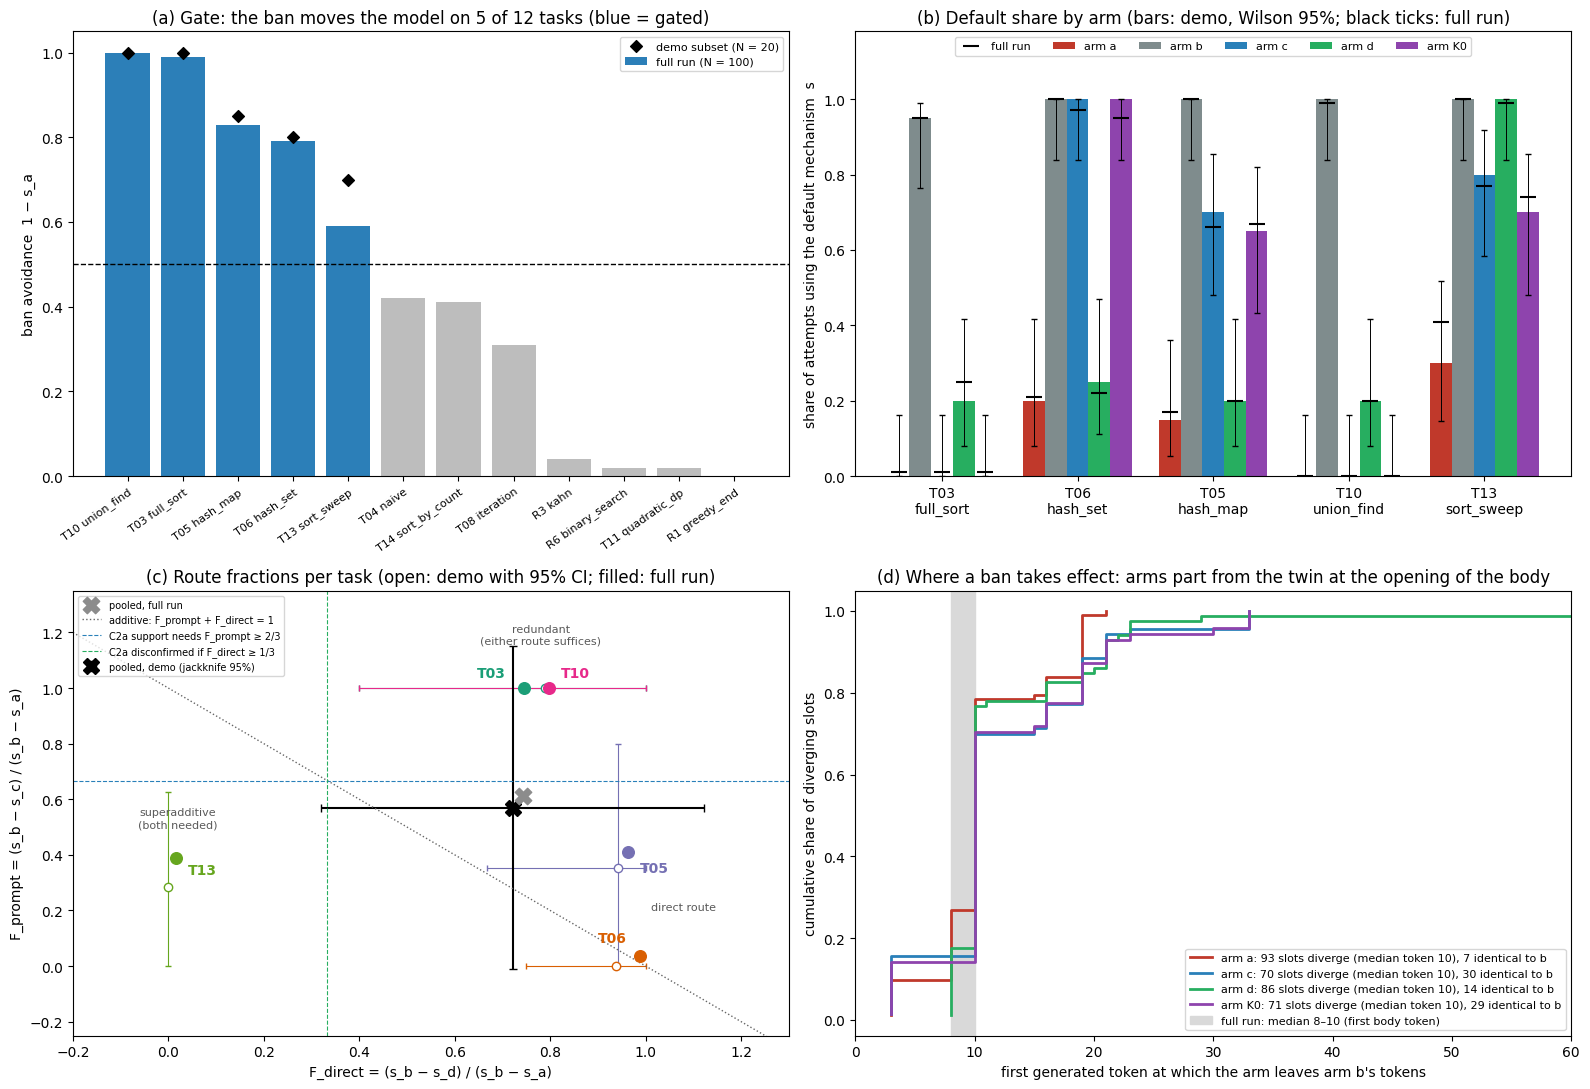

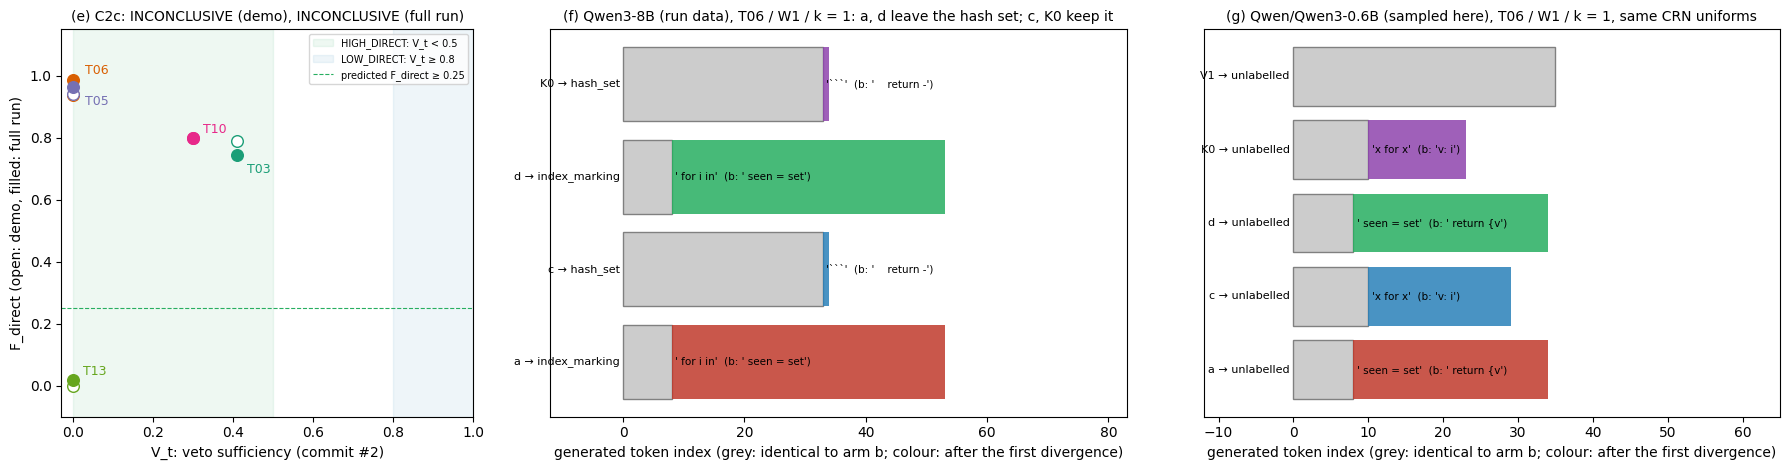

In [21]:
# ---- notebook: visualisation (the run's figures/fig1-fig4 redrawn from this notebook's results) ----
ARM_COL = {"a": "#c0392b", "b": "#7f8c8d", "c": "#2980b9", "d": "#27ae60", "K0": "#8e44ad", "V1": "#f39c12"}
TASK_COL = dict(zip(DEMO_TASKS, ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e"]))
OFF_C = {"T03": (-34, 8), "T10": (8, 8), "T06": (-30, 10), "T05": (8, -14), "T13": (8, -12)}  # label offsets, panel (c)
OFF_E = {"T06": (8, 4), "T05": (8, -13), "T10": (7, 4), "T03": (7, -13), "T13": (7, 4)}      # label offsets, panel (e)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
# (a) gate: ban avoidance per bench task (full run, N = 100 arm-a rows per task)
ax = axes[0, 0]
order = sorted(STAGE_A, key=lambda t: -gate[t]["avoidance"])
ax.bar(range(len(order)), [gate[t]["avoidance"] for t in order],
       color=["#2c7fb8" if gate[t]["gated"] else "#bdbdbd" for t in order], label="full run (N = 100)")
ax.scatter([order.index(t) for t in DEMO_TASKS], [gate_demo[t]["avoidance"] for t in DEMO_TASKS], marker="D", color="k",
           zorder=3, label="demo subset (N = 20)")
ax.axhline(THRESHOLDS["gate_avoidance"], ls="--", color="k", lw=1)
ax.set_xticks(range(len(order)), [f"{t} {default_of(t)}" for t in order], fontsize=8, rotation=35, ha="right",
              rotation_mode="anchor")
ax.set_ylabel("ban avoidance  1 − s_a")
ax.set_title("(a) Gate: the ban moves the model on 5 of 12 tasks (blue = gated)")
ax.legend(fontsize=8)

# (b) default share per arm (demo, Wilson 95%) with the full-run value as a black tick
ax = axes[0, 1]
wdt = 0.16
for j, a in enumerate(meta["arms"]):
    xs = np.arange(len(DEMO_TASKS)) + (j - 2) * wdt
    s = np.array([shares[t][a]["s"] for t in DEMO_TASKS])
    lo = s - np.array([shares[t][a]["ci95"][0] for t in DEMO_TASKS])
    hi = np.array([shares[t][a]["ci95"][1] for t in DEMO_TASKS]) - s
    ax.bar(xs, s, wdt, color=ARM_COL[a], label=f"arm {a}", yerr=[lo, hi], capsize=2, error_kw={"lw": 0.7})
    ax.scatter(xs, [ref_sh[t][a]["s"] for t in DEMO_TASKS], marker="_", s=140, color="k", zorder=3,
               label="full run" if j == 0 else None)
ax.set_xticks(range(len(DEMO_TASKS)), [f"{t}\n{default_of(t)}" for t in DEMO_TASKS])
ax.set_ylim(0, 1.18)
ax.set_ylabel("share of attempts using the default mechanism  s")
ax.set_title("(b) Default share by arm (bars: demo, Wilson 95%; black ticks: full run)")
ax.legend(ncol=6, fontsize=8, loc="upper center")

# (c) route fractions per task: demo (open, 95% CI) and full run (filled)
ax = axes[1, 0]
for t in DEMO_TASKS:
    v, f = route["per_task"][t], fr["per_task"][t]
    x, y = v["F_direct"]["point"], v["F_prompt"]["point"]
    ax.errorbar(x, y, xerr=[[max(0, x - v["F_direct"]["ci95"][0])], [max(0, v["F_direct"]["ci95"][1] - x)]],
                yerr=[[max(0, y - v["F_prompt"]["ci95"][0])], [max(0, v["F_prompt"]["ci95"][1] - y)]],
                fmt="o", color=TASK_COL[t], mfc="white", capsize=2, lw=0.8)
    ax.scatter(f["F_direct"]["point"], f["F_prompt"]["point"], color=TASK_COL[t], s=70, zorder=3)
    ax.annotate(t, (f["F_direct"]["point"], f["F_prompt"]["point"]), textcoords="offset points", xytext=OFF_C[t],
                color=TASK_COL[t], fontsize=10, fontweight="bold")
px, py = route["point"]["F_direct"], route["point"]["F_prompt"]
jd, jp = route["intervals"]["F_direct"]["jackknife"], route["intervals"]["F_prompt"]["jackknife"]
ax.errorbar(px, py, xerr=[[px - jd[0]], [jd[1] - px]], yerr=[[py - jp[0]], [jp[1] - py]], fmt="X", color="k", ms=11,
            capsize=3, label="pooled, demo (jackknife 95%)")
ax.scatter(fr["point"]["F_direct"], fr["point"]["F_prompt"], marker="X", s=140, color="0.55", zorder=4,
           label="pooled, full run")
xx = np.linspace(-0.2, 1.3, 10)
ax.plot(xx, 1 - xx, ls=":", color="0.4", lw=1, label="additive: F_prompt + F_direct = 1")
ax.axhline(THRESHOLDS["F_confirm"], ls="--", color=ARM_COL["c"], lw=0.8, label="C2a support needs F_prompt ≥ 2/3")
ax.axvline(THRESHOLDS["F_direct_disconfirm"], ls="--", color=ARM_COL["d"], lw=0.8, label="C2a disconfirmed if F_direct ≥ 1/3")
for txt, (tx, ty) in {"redundant\n(either route suffices)": (0.78, 1.16), "direct route": (1.08, 0.2),
                      "superadditive\n(both needed)": (0.02, 0.5)}.items():
    ax.text(tx, ty, txt, fontsize=8, color="0.35", ha="center")
ax.set_xlim(-0.2, 1.3)
ax.set_ylim(-0.25, 1.35)
ax.set_xlabel("F_direct = (s_b − s_d) / (s_b − s_a)")
ax.set_ylabel("F_prompt = (s_b − s_c) / (s_b − s_a)")
ax.set_title("(c) Route fractions per task (open: demo with 95% CI; filled: full run)")
ax.legend(fontsize=7, loc="upper left")

# (d) first divergence from arm b under CRN, pooled over the demo tasks
ax = axes[1, 1]
for X in ("a", "c", "d", "K0"):
    vals = np.sort([v for t in DEMO_TASKS for v in crn[t]["first_divergence"].get(X, {}).get("values", [])])
    n_id = sum(crn[t]["first_divergence"].get(X, {}).get("n_identical_to_b", 0) for t in DEMO_TASKS)
    if len(vals):
        ax.step(vals, np.arange(1, len(vals) + 1) / len(vals), where="post", color=ARM_COL[X], lw=2,
                label=f"arm {X}: {len(vals)} slots diverge (median token {np.median(vals):.0f}), {n_id} identical to b")
ax.axvspan(8, 10, color="0.85", zorder=0, label="full run: median 8–10 (first body token)")
ax.set_xlim(0, 60)
ax.set_xlabel("first generated token at which the arm leaves arm b's tokens")
ax.set_ylabel("cumulative share of diverging slots")
ax.set_title("(d) Where a ban takes effect: arms part from the twin at the opening of the body")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()


# (e) C2c and (f, g) one CRN slot, token by token
def _slot_bars(ax, rows_by_arm: dict[str, dict[str, Any]], title: str) -> None:
    b = rows_by_arm["b"]["token_ids"]
    arms_ = [a for a in ("a", "c", "d", "K0", "V1") if a in rows_by_arm]
    for i, a in enumerate(arms_):
        x = rows_by_arm[a]["token_ids"]
        m = min(len(x), len(b))
        d = next((j for j in range(m) if x[j] != b[j]), None if len(x) == len(b) else m)
        same = len(x) if d is None else d
        ax.barh(i, same, color="0.8", edgecolor="0.5")
        if d is not None:
            ax.barh(i, len(x) - d, left=d, color=ARM_COL[a], alpha=0.85)
            ax.text(d + 0.5, i, f"{tok.decode(x[d:d + 3])!r}  (b: {tok.decode(b[d:d + 3])!r})", va="center", fontsize=7.5)
        ax.text(-0.5, i, f"{a} → {rows_by_arm[a].get('label', '?')}", va="center", ha="right", fontsize=8)
    ax.set_yticks([])
    ax.set_xlabel("generated token index (grey: identical to arm b; colour: after the first divergence)")
    ax.set_title(title, fontsize=10)
    ax.set_xlim(-12, max(len(r["token_ids"]) for r in rows_by_arm.values()) + 30)


fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1, 1.4, 1.4]})
ax = axes[0]
for r in c2c["rows"]:
    if r["gated"]:
        ax.scatter(r["V"], r["F_direct"], facecolors="white", edgecolors=TASK_COL[r["task"]], s=70, zorder=3)
        ax.scatter(r["V"], fr["per_task"][r["task"]]["F_direct"]["point"], color=TASK_COL[r["task"]], s=70, zorder=3)
        ax.annotate(r["task"], (r["V"], fr["per_task"][r["task"]]["F_direct"]["point"]), textcoords="offset points",
                    xytext=OFF_E[r["task"]], fontsize=9, color=TASK_COL[r["task"]])
ax.axvspan(0, THRESHOLDS["veto_high_direct"], color=ARM_COL["d"], alpha=0.08, label="HIGH_DIRECT: V_t < 0.5")
ax.axvspan(THRESHOLDS["veto_low_direct"], 1, color=ARM_COL["c"], alpha=0.08, label="LOW_DIRECT: V_t ≥ 0.8")
ax.axhline(THRESHOLDS["pred_high_direct_F"], ls="--", color=ARM_COL["d"], lw=0.8, label="predicted F_direct ≥ 0.25")
ax.set_xlim(-0.03, 1.0)
ax.set_ylim(-0.1, 1.15)
ax.set_xlabel("V_t: veto sufficiency (commit #2)")
ax.set_ylabel("F_direct (open: demo, filled: full run)")
ax.set_title(f"(e) C2c: {c2c['decision']} (demo), {ref_c2c['decision']} (full run)", fontsize=10)
ax.legend(fontsize=7, loc="upper right")
slot8b = {a: r for a, r in next(e for e in EXAMPLES if (e["metadata_task"], e["metadata_template"], e["metadata_k"])
                                == ("T06", "W1", 1))["arm_rows"].items()}
_slot_bars(axes[1], slot8b, "(f) Qwen3-8B (run data), T06 / W1 / k = 1: a, d leave the hash set; c, K0 keep it")
t_, w_, k_ = ENGINE_TASKS[0], ENGINE_TEMPLATES[0], ENGINE_SLOTS[0]
slot_small = {a: {**eng[(t_, w_, k_, a)], "label": "unlabelled"} for a in ENGINE_ARMS}
_slot_bars(axes[2], slot_small, f"(g) {ENGINE_MODEL_ID} (sampled here), {t_} / {w_} / k = {k_}, same CRN uniforms")
plt.tight_layout()
plt.show()

In [22]:
# ---- notebook: demo subset vs full run, per task and pooled ----
import pandas as pd


def _reading(f: dict[str, Any]) -> str:  # notebook: the README's per-task reading, from the full-run route fractions
    fp, fd = f["F_prompt"]["point"], f["F_direct"]["point"]
    if fp >= 0.5 and fd >= 0.5:
        return "redundant (either route suffices)"
    if fd >= 0.5:
        return "direct route"
    if fp >= 0.5:
        return "prompt route"
    return "superadditive (both needed)"


recs = []
for t in DEMO_TASKS:
    v, f = route["per_task"][t], fr["per_task"][t]
    recs.append({"task": t, "default": default_of(t),
                 **{f"s_{a}": f"{shares[t][a]['s']:.2f} ({ref_sh[t][a]['s']:.2f})" for a in meta["arms"]},
                 **{k: f"{v[k]['point']:.2f} ({f[k]['point']:.2f})" for k in ("F_prompt", "F_direct", "I", "F_K0")},
                 "P_open SIG / NEU (full run)": "{:.2f} / {:.2f}".format(*[meta["full_run_reference"]["prefill_P_open"][t][pf]
                                                                           for pf in ("SIG", "NEU")]),
                 "mechanism (full run)": _reading(f)})
recs.append({"task": "pooled", "default": f"{route['n_tasks']} gated tasks",
             **{k: f"{route['point'][k]:.2f} ({fr['point'][k]:.2f})" for k in ("F_prompt", "F_direct", "I", "F_K0")},
             "mechanism (full run)": f"C2a {fr['verdict']} (demo: {route['verdict']})"})
table = pd.DataFrame(recs).set_index("task").fillna("")
print("each cell: demo subset value (full-run value)")
display(table)

print(f"C2a (prompt route carries >= 2/3 of the ban): demo {route['verdict']} | full run {fr['verdict']} "
      f"(jackknife F_prompt {_ci(fr['intervals']['F_prompt']['jackknife'])}, F_direct {_ci(fr['intervals']['F_direct']['jackknife'])})")
print(f"C2c (veto sufficiency predicts F_direct):      demo {c2c['decision']} | full run {ref_c2c['decision']}")
print(f"engine tests on {ENGINE_MODEL_ID}: U1 {res['U1_identical_fraction']:.2f}, U2 {res['U2_splice_ban_ban_equals_a']:.2f} / "
      f"{res['U2_splice_twin_twin_equals_b']:.2f}, U3 zero-mass {res['U3_pass']}, span-drop == masked knockout {res['U3_spandrop_pass']}")
print(f"CPU tests: " + ", ".join(f"{k} {'pass' if v['pass'] else 'FAIL'}" for k, v in tests_cpu.items()))

each cell: demo subset value (full-run value)


,default,s_a,s_b,s_c,s_d,s_K0,F_prompt,F_direct,I,F_K0,P_open SIG / NEU (full run),mechanism (full run)
task,,,,,,,,,,,,
T03,full_sort,0.00 (0.01),0.95 (0.95),0.00 (0.01),0.20 (0.25),0.00 (0.01),1.00 (1.00),0.79 (0.74),-0.79 (-0.74),1.00 (1.00),0.98 / -0.01,redundant (either route suffices)
T06,hash_set,0.20 (0.21),1.00 (1.00),1.00 (0.97),0.25 (0.22),1.00 (0.95),0.00 (0.04),0.94 (0.99),0.06 (-0.03),0.00 (0.06),1.00 / -0.01,direct route
T05,hash_map,0.15 (0.17),1.00 (1.00),0.70 (0.66),0.20 (0.20),0.65 (0.67),0.35 (0.41),0.94 (0.96),-0.29 (-0.37),0.41 (0.40),1.00 / 0.01,direct route
T10,union_find,0.00 (0.00),1.00 (0.99),0.00 (0.00),0.20 (0.20),0.00 (0.00),1.00 (1.00),0.80 (0.80),-0.80 (-0.80),1.00 (1.00),1.00 / 0.00,redundant (either route suffices)
T13,sort_sweep,0.30 (0.41),1.00 (1.00),0.80 (0.77),1.00 (0.99),0.70 (0.74),0.29 (0.39),0.00 (0.02),0.71 (0.59),0.43 (0.44),1.00 / -0.12,superadditive (both needed)
pooled,5 gated tasks,,,,,,0.57 (0.61),0.72 (0.74),-0.29 (-0.36),0.60 (0.62),,C2a DISCONFIRMED (demo: DISCONFIRMED)


C2a (prompt route carries >= 2/3 of the ban): demo DISCONFIRMED | full run DISCONFIRMED (jackknife F_prompt [  0.06,   1.17], F_direct [  0.38,   1.11])
C2c (veto sufficiency predicts F_direct):      demo INCONCLUSIVE | full run INCONCLUSIVE
engine tests on Qwen/Qwen3-0.6B: U1 1.00, U2 1.00 / 1.00, U3 zero-mass True, span-drop == masked knockout True
CPU tests: T3 pass, T4 pass, T5 pass


## Takeaways

1. **A ban does not simply remove the banned token from the model's output.** It steers the model to another algorithm, and
   only on some tasks. Just 5 of 12 bench tasks are gated, and the weakest wording, W4 (*"X is not allowed here."*), avoids the
   default only 19% of the time.
2. **Which route carries the ban depends on the task.** Pooled over the gated tasks, the prompt route does **not** carry ≥ 2/3
   of the effect, so C2a is disconfirmed: F_prompt 0.61 and F_direct 0.74 in the full run, with the demo close by. Per task:
   - T05/T06 read the ban sentence **directly**: arm d reproduces the ban, while c and K0 do not.
   - On T03/T10 the information is **redundant**: either route alone suffices.
   - T13 needs **both** routes.
3. **Where it takes effect is the opening of the function body.** Under common random numbers every arm copies the twin until
   the first body token. Forcing the default's opening up to that token undoes the ban completely (P_open 0.98–1.00), while a
   neutral `def` line undoes none of it.
4. **Subtracting one n-gram is not the ban.** A one-shot veto of the default's distinctive n-gram rarely changes the mechanism:
   V_t ≤ 0.41, because the model renames or re-tokenises around it. C2c therefore stays inconclusive.

## Scaling back up

- **Analysis.** The bootstrap, permutation and null sizes and the CPU tests already run at their full-run values; T4 and
  T5 reproduce the run's recorded values exactly. To analyse all 13,030 rows, point `load_rows()` at the run's
  `data/samples.jsonl` and set `N_SLOTS = 20`. That reproduces `results/route.json`, which the run's audit re-derived with
  0 mismatches.
- **Engine.** Raise `ENGINE_SLOTS`, `ENGINE_TEMPLATES` and `ENGINE_MAX_NEW` (up to 1024) for more and longer samples, or use
  `ENGINE_MODEL_ID = "Qwen/Qwen3-1.7B"`. In a probe on this demo's slot, 1.7B shows the T06 direct-route pattern: arm d
  reproduced the ban's program token for token, and arms c and K0 the twin's. `"Qwen/Qwen3-8B"` with `ENGINE_BATCH = 40` on a
  ≥ 24 GB GPU is the original setting. The full run took about 1.8 GPU-hours on an L4, plus labelling with the frozen
  runtime+AST+judge labellers (USD 0.105).